<a href="https://colab.research.google.com/github/ZainabSultan2005/MLmodels/blob/main/Copy_of_PAI_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [282]:
import requests
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
import ast
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [283]:
from google.colab import userdata

API_TOKEN = userdata.get('TMDB_TOKEN')

# Connecting to TMDB
We imported the requests library that help our notebook connect to the website. We loaded the API token in 'secret' and loaded it in our code so that we do not have to type the API token in our code. If we do that and public the notebook, unauthorized persons can use our API to wrongfully access the TMDB website.

In [284]:
url = "https://api.themoviedb.org/3/discover/movie"

In [285]:
headers = {
    "Authorization": f"Bearer {API_TOKEN}",  #TMDB recognized this pattern so we use bearer before API Token
    "accept": "application/json" #it tells TMDB that program prefers response in json format
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [286]:
data = response.json() #converts json format to python data structures

print(data.keys())
# Testing data format
print(data["results"][0]["title"])

dict_keys(['page', 'results', 'total_pages', 'total_results'])
Iron Man


Every API request needs two parameters. First is the url and the other is authorization i.e API token. We sent the request using request libarary and get a json in response that we convert to a python dictionary. Our status code is 200 which shows that we successfully got the access.

In [287]:
all_movies = []

params = {
    "primary_release_date.gte": "2016-01-01",
    "primary_release_date.lte": "2016-12-31",
    "sort_by": "vote_count.desc",
    "page": 1
}

for i in range(5):

    params["page"] = i + 1

    response = requests.get(
        url,
        headers=headers,
        params=params
    )

    data = response.json()
    movies = data["results"]

    all_movies.extend(movies)

print(response.status_code)
print("Movies retrieved:", len(all_movies))
print(all_movies[0]["title"])
print(all_movies[-1]["title"])

200
Movies retrieved: 100
Deadpool
The Invitation


We created an empty list and defined the parameters for our data (like the release dates). Then we retrieved the relevant data, one page at a time. In total we got 100 movie. The code below ensures that in our list of movies, all movie ids are unique.

In [288]:
# Preserve the 100 movies we already collected for 2016
movies_by_year = {
    2016: all_movies.copy()
}

# Collect movies for 2017 to 2026
for year in range(2017, 2027):

    year_movies = []

    for page in range(1, 6):

        params = {
            "primary_release_date.gte": f"{year}-01-01",
            "primary_release_date.lte": f"{year}-12-31",
            "sort_by": "vote_count.desc",
            "page": page
        }

        response = requests.get(
            url,
            headers=headers,
            params=params
        )

        data = response.json()

        year_movies.extend(data["results"])

    movies_by_year[year] = year_movies

    print(year, ":", len(year_movies), "movies collected")

2017 : 100 movies collected
2018 : 100 movies collected
2019 : 100 movies collected
2020 : 100 movies collected
2021 : 100 movies collected
2022 : 100 movies collected
2023 : 100 movies collected
2024 : 100 movies collected
2025 : 100 movies collected
2026 : 100 movies collected


In [289]:
#Removing duplicates
def remove_duplicates(year):
    movie_ids = []
    z = 0

    for movies in year:
        id = year[z]["id"]
        movie_ids.append(id)
        z += 1

    movie_unique = set(movie_ids)

    print(len(movie_ids))
    print(len(movie_unique))


for keys, values in movies_by_year.items():
    print("Year:", keys)
    remove_duplicates(values)


Year: 2016
100
100
Year: 2017
100
100
Year: 2018
100
100
Year: 2019
100
100
Year: 2020
100
100
Year: 2021
100
100
Year: 2022
100
100
Year: 2023
100
100
Year: 2024
100
100
Year: 2025
100
100
Year: 2026
100
100


In [290]:
for keys,values in movies_by_year.items():
  remove_duplicates(movies_by_year[keys])


100
100
100
100
100
100
100
100
100
100
100
100
100
100
100
100
100
100
100
100
100
100


In [291]:
details_url = "https://api.themoviedb.org/3/movie"

all_movie_details = []
movie_ids = []

for keys,values in movies_by_year.items():
  for items in values:
    movie_ids.append(items["id"])



for items in movie_ids:
    response = requests.get(
        f"{details_url}/{items}",
        headers=headers
    )

    movie_details = response.json()
    all_movie_details.append(movie_details)


In [292]:
print(len(all_movie_details))
print(all_movie_details[0])



1100
{'adult': False, 'backdrop_path': '/rFj9IKlL75B2pXhZA60jkNWvxeW.jpg', 'belongs_to_collection': {'id': 448150, 'name': 'Deadpool Collection', 'poster_path': '/30c5jO7YEXuF8KiWXLg9m28GWDA.jpg', 'backdrop_path': '/dTq7mGyAR5eAydR532feWfjJjzm.jpg'}, 'budget': 58000000, 'genres': [{'id': 28, 'name': 'Action'}, {'id': 12, 'name': 'Adventure'}, {'id': 35, 'name': 'Comedy'}], 'homepage': 'https://www.20thcenturystudios.com/movies/deadpool', 'id': 293660, 'imdb_id': 'tt1431045', 'origin_country': ['US'], 'original_language': 'en', 'original_title': 'Deadpool', 'overview': 'The origin story of former Special Forces operative turned mercenary Wade Wilson, who, after being subjected to a rogue experiment that leaves him with accelerated healing powers, adopts the alter ego Deadpool. Armed with his new abilities and a dark, twisted sense of humor, Deadpool hunts down the man who nearly destroyed his life.', 'popularity': 21.5904, 'poster_path': '/3E53WEZJqP6aM84D8CckXx4pIHw.jpg', 'production_c

As of now, we have retrieved 1100 movies from year 2016 to 2026 and verified that all movie ids are unique. Using those unique ids, we have created another list of ductionaries that contains the details of all 1100 movies. This is our data that we have to clean and train model on.

In [293]:
df = pd.DataFrame(all_movie_details)  #sare data ko humne DataFrame mein convert kar diya hai


In [294]:
df.to_csv("moviesRaw.csv", index = False)
#index=False tells pandas not to save the DataFrame's row index as an extra column in the csv file
#bcz by default index ka ik separate column banta hai jab hum csv mein dalte data

In [295]:
data = pd.read_csv("moviesRaw.csv")
#now we will inspect our data

In [296]:
data.shape  #total 1100 (rows) movies hain, with 27 (cols) attributes

(1100, 27)

In [297]:
data.head() #by default gives us the first five values

,adult,backdrop_path,belongs_to_collection,budget,genres,homepage,id,imdb_id,origin_country,original_language,...,revenue,runtime,softcore,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,/rFj9IKlL75B2pXhZA60jkNWvxeW.jpg,"{'id': 448150, 'name': 'Deadpool Collection', ...",58000000,"[{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...",https://www.20thcenturystudios.com/movies/dead...,293660,tt1431045,['US'],en,...,782837347,108,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Feel the love.,Deadpool,False,7.626,33689
1,False,/7FWlcZq3r6525LWOcvO9kNWurN1.jpg,"{'id': 131295, 'name': 'Captain America Collec...",250000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 28, '...",https://www.marvel.com/movies/captain-america-...,271110,tt3498820,['US'],en,...,1155046416,147,False,"[{'english_name': 'Romanian', 'iso_639_1': 'ro...",Released,United we stand. Divided we fall.,Captain America: Civil War,False,7.455,24921
2,False,/kkoiH8ZWxJ9WSAjOadGtuHUQxbm.jpg,"{'id': 618529, 'name': 'Doctor Strange Collect...",180000000,"[{'id': 14, 'name': 'Fantasy'}, {'id': 12, 'na...",https://www.marvel.com/movies/doctor-strange,284052,tt1211837,['US'],en,...,676343174,115,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,The impossibilities are endless.,Doctor Strange,False,7.425,24261
3,False,/wAk0yKrhAmvsoMvlKs4QImhvK5X.jpg,"{'id': 531242, 'name': 'Suicide Squad Collecti...",175000000,"[{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...",http://www.suicidesquad.com/,297761,tt1386697,['US'],en,...,749200054,122,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Worst. Heroes. Ever.,Suicide Squad,False,5.900,22660
4,False,/8MUZz7oPXQftFTslZpRP3CVMOoq.jpg,NaN,47000000,"[{'id': 18, 'name': 'Drama'}, {'id': 878, 'nam...",http://www.arrivalmovie.com/,329865,tt2543164,['US'],en,...,203388186,116,False,"[{'english_name': 'Chinese', 'iso_639_1': 'zh'...",Released,Why are they here?,Arrival,False,7.638,20242


In [298]:
data.tail() #last five rows

,adult,backdrop_path,belongs_to_collection,budget,genres,homepage,id,imdb_id,origin_country,original_language,...,revenue,runtime,softcore,spoken_languages,status,tagline,title,video,vote_average,vote_count
1095,False,/4A3r1AjJg9Wa6ms3MGOScetCY0o.jpg,NaN,180000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",https://www.diggermovie.com,1248832,tt31450459,['US'],en,...,50850116,129,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,A man. A plan. A meltdown.,Digger,False,7.498,542
1096,False,/caBIySpwuFi2i7ynvHIlnxJLOdN.jpg,"{'id': 1560779, 'name': 'Batman: Knightfall Co...",0,"[{'id': 16, 'name': 'Animation'}, {'id': 28, '...",https://www.warnerbros.com/movies/batman-knigh...,1560520,tt32333324,['US'],en,...,0,79,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,NaN,Batman: Knightfall Part 1: Knightfall,False,9.086,515
1097,False,/hL5EIk48251OXlbIbRJq3yaBHk8.jpg,NaN,0,"[{'id': 35, 'name': 'Comedy'}, {'id': 80, 'nam...",https://www.netflix.com/title/81715790,949838,tt36304003,['US'],en,...,0,105,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,The night is young. He isn't.,72 HOURS,False,6.713,514
1098,False,/uNToXatdunyvWXyXMrTI1nLvh6r.jpg,NaN,0,"[{'id': 35, 'name': 'Comedy'}, {'id': 878, 'na...",https://www.20thcenturystudios.com/movies/mike...,1115544,tt27552099,['US'],en,...,0,107,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,"A time-traveling, double-crossing, ass-kicking...",Mike & Nick & Nick & Alice,False,6.665,509
1099,False,/seuG9UslSFybML8C4enbrE6Hsyz.jpg,NaN,3000000,"[{'id': 27, 'name': 'Horror'}, {'id': 9648, 'n...",https://ironlung.com,1116201,tt27564844,['US'],en,...,51226173,125,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,This is not an expedition. It's an execution.,Iron Lung,False,6.745,495


In [299]:
data.columns.tolist() #list of attributes agaye

['adult',
 'backdrop_path',
 'belongs_to_collection',
 'budget',
 'genres',
 'homepage',
 'id',
 'imdb_id',
 'origin_country',
 'original_language',
 'original_title',
 'overview',
 'popularity',
 'poster_path',
 'production_companies',
 'production_countries',
 'release_date',
 'revenue',
 'runtime',
 'softcore',
 'spoken_languages',
 'status',
 'tagline',
 'title',
 'video',
 'vote_average',
 'vote_count']

In [300]:
data.info() #info sey hamare pass data sey related kaafi cheeze ati hai
# aur usko dekh ke humme pata chal raha hai ke hamare data mein missing / null values hain

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  1100 non-null   bool   
 1   backdrop_path          1099 non-null   object 
 2   belongs_to_collection  392 non-null    object 
 3   budget                 1100 non-null   int64  
 4   genres                 1100 non-null   object 
 5   homepage               1024 non-null   object 
 6   id                     1100 non-null   int64  
 7   imdb_id                1099 non-null   object 
 8   origin_country         1100 non-null   object 
 9   original_language      1100 non-null   object 
 10  original_title         1100 non-null   object 
 11  overview               1100 non-null   object 
 12  popularity             1100 non-null   float64
 13  poster_path            1099 non-null   object 
 14  production_companies   1100 non-null   object 
 15  prod

In [301]:
data.isna().sum() #ab woh kitni null values hain hum check kare gey isna().sum() sey

,0
adult,0
backdrop_path,1
belongs_to_collection,708
budget,0
genres,0
homepage,76
id,0
imdb_id,1
origin_country,0
original_language,0


In [302]:
data.describe()
# yahan sey humme ye pata chalta hai ke kuch values zero hain
# for example min for budget is zero, ye bhi missing values mein count hoga (bcz data is not complete)
# also agar hum data.isna().sum() kare gey tou usmein zero valued values nahi ayi gi
# for this we will use (data[col] == 0).sum() (ye kaam agey kiya hai)

,budget,id,popularity,revenue,runtime,vote_average,vote_count
count,1.100000e+03,1.100000e+03,1100.000000,1.100000e+03,1100.000000,1100.000000,1100.000000
mean,6.183222e+07,6.478979e+05,12.842583,1.882768e+08,115.122727,6.943631,4641.105455
std,7.497192e+07,3.185277e+05,22.277120,3.210664e+08,20.308683,0.673874,4398.673412
min,0.000000e+00,1.456400e+04,0.017300,0.000000e+00,12.000000,3.987000,495.000000
25%,9.000000e+06,4.018530e+05,5.947675,6.151455e+06,102.000000,6.484250,1866.500000
50%,3.500000e+07,5.652270e+05,8.484500,6.083273e+07,112.000000,6.939000,3188.500000
75%,9.000000e+07,8.412598e+05,12.931575,2.139270e+08,126.000000,7.397000,5590.000000
max,6.588000e+08,1.698863e+06,383.102800,2.942661e+09,242.000000,9.086000,33689.000000


In [303]:
data.nunique()

,0
adult,1
backdrop_path,1099
belongs_to_collection,256
budget,212
genres,493
homepage,1015
id,1100
imdb_id,1099
origin_country,56
original_language,16


In [304]:
categorical_columns = [ #frequency distribution of some columns (sare columns keleye we will use data.columns.tolist())
    "original_language",
    "status",
    "video",
    "origin_country"
]

for col in categorical_columns:
    print("\nColumn:", col)
    print(df[col].value_counts())


Column: original_language
original_language
en    1021
ja      17
fr      14
es      13
ko       9
it       6
no       4
zh       3
fi       2
pl       2
de       2
da       2
pt       2
tr       1
lv       1
te       1
Name: count, dtype: int64

Column: status
status
Released    1100
Name: count, dtype: int64

Column: video
video
False    1100
Name: count, dtype: int64

Column: origin_country
origin_country
[US]                    879
[GB]                     32
[GB, US]                 25
[JP]                     19
[US, GB]                 17
[FR]                     15
[CA, US]                 14
[ES]                     10
[KR]                      9
[AU]                      7
[AU, US]                  7
[IT]                      5
[DK]                      4
[PL]                      3
[US, CA]                  3
[CN, US]                  3
[NO]                      3
[FI]                      2
[CN, HK]                  2
[MX]                      2
[CN]                      2

In [305]:
data.duplicated().sum()

np.int64(0)

In [306]:
data.memory_usage(deep = True).sum()  # 2561442 bytes

np.int64(2548981)

In [307]:
#Data Cleaning and Preprocessing
#(step 5)
#part A (missing values)

print("total missing values: ", data.isna().sum())
print("missing percentage: ", data.isna().sum() / len(data) * 100)

total missing values:  adult                      0
backdrop_path              1
belongs_to_collection    708
budget                     0
genres                     0
homepage                  76
id                         0
imdb_id                    1
origin_country             0
original_language          0
original_title             0
overview                   0
popularity                 0
poster_path                1
production_companies       0
production_countries       0
release_date               0
revenue                    0
runtime                    0
softcore                   0
spoken_languages           0
status                     0
tagline                   43
title                      0
video                      0
vote_average               0
vote_count                 0
dtype: int64
missing percentage:  adult                     0.000000
backdrop_path             0.090909
belongs_to_collection    64.363636
budget                    0.000000
genres              

In [308]:
zero_colums = ["revenue", "budget"] #sirf ye dono columns isleye liye hain kuikeh sirf unhi dono ki min value zero thi
totalZeroValues = [0, 0]

j = 0
for i in zero_colums:
  totalZeroValues[j] += (data[i] == 0).sum()
  j += 1

print(totalZeroValues)


[np.int64(201), np.int64(159)]


In [309]:
dataCopy = data.copy() #making a copy of our original data

In [310]:
for i in zero_colums:
  dataCopy.loc[dataCopy[i] == 0, i] = np.nan

# df.loc[row, col]  gives us data of that specific row and col
# here df.loc[dataCopy[i] == 0, i] means that,
# i (col) jo hai uski woh rows jahan value 0 hai usko Nan kardo
# Nan isleye kiya hai take ik hi dafa saari rows drop kar deyn

In [311]:
dataCopy.isna().sum()
# ab yahan pe revenue keleye bhi null values arahi hain
# phele nahi tha (bcz woh values zero thin, aur isna() usko include nahi karta)

,0
adult,0
backdrop_path,1
belongs_to_collection,708
budget,159
genres,0
homepage,76
id,0
imdb_id,1
origin_country,0
original_language,0


In [312]:
dataCopy.dropna(subset=["revenue"], inplace=True) #inplace True sey actual dataCopy sey remove hojaye ga

#shape tells use that we have removed 201 null revenue rows
print(dataCopy.shape)
print(data.shape)

#uska output zero aye ga, bcz ab revenue aur budget mein koi missing value nahi hai
print(dataCopy["revenue"].isna().sum())


(899, 27)
(1100, 27)
0


In [313]:
dataCopy["budget"].describe()
#now we have to deal with the missing values in budget
#we can see here that the mean is approx 73 million and median is approx 42 million
#this tells us that our data is right skewed (contain more large values)
#thats why we are choosing to replace the missing values with the median of the data


,budget
count,8.670000e+02
mean,7.314955e+07
std,7.780635e+07
min,7.000000e+00
25%,1.800000e+07
50%,4.200000e+07
75%,1.040000e+08
max,6.588000e+08


In [314]:

dataCopy["budget"] = dataCopy["budget"].fillna(dataCopy["budget"].median())

#now we dont have any missing values left
print(dataCopy["budget"].isna().sum())

0


In [315]:
#for the column "belongs_to_collection" we are replacing the Nan with a label "no collection"
#bcz those movies do not belong to any collection
#similar reason for "homepage" and "tagline"

dataCopy["belongs_to_collection"] = dataCopy["belongs_to_collection"].fillna("no collection")
print(dataCopy["belongs_to_collection"].isna().sum())

dataCopy["homepage"] = dataCopy["homepage"].fillna("no homepage provided")
dataCopy["tagline"] = dataCopy["tagline"].fillna("no tagline provided")

print(dataCopy.isna().sum().sum())  #now we dont have any missing values

0
0


In [316]:
#making a copy of the data to introduct 5% null values

fivePercentNullData = dataCopy.copy()

#random 5% data uthaya hai
fivePercent = fivePercentNullData.sample(frac = 0.05, random_state = 1)

#jo random data uthaya hai wahan pe input_feature ko Nan kar diya
input_feature = ["budget", "runtime", "original_language"]

for i in input_feature:
  fivePercentNullData.loc[fivePercent.index, i] = np.nan

print("Five percent missing values (before):\n", fivePercentNullData.isna().sum())

Five percent missing values (before):
 adult                     0
backdrop_path             0
belongs_to_collection     0
budget                   45
genres                    0
homepage                  0
id                        0
imdb_id                   0
origin_country            0
original_language        45
original_title            0
overview                  0
popularity                0
poster_path               0
production_companies      0
production_countries      0
release_date              0
revenue                   0
runtime                  45
softcore                  0
spoken_languages          0
status                    0
tagline                   0
title                     0
video                     0
vote_average              0
vote_count                0
dtype: int64


In [317]:
fivePercentNullData[["budget", "runtime"]].describe()

,budget,runtime
count,8.540000e+02,854.000000
mean,7.193462e+07,116.538642
std,7.700978e+07,20.203485
min,3.500000e+04,57.000000
25%,1.800000e+07,102.000000
50%,4.200000e+07,113.000000
75%,1.000000e+08,128.000000
max,6.588000e+08,215.000000


In [318]:
#for budget we are filling the null values with the median
fivePercentNullData["budget"] = fivePercentNullData["budget"].fillna(fivePercentNullData["budget"].median())

#for runtime we are filling the null values with mean (bcz there is less difference between mean and median of runtime
#(suggesting that it may be symmetrically skewed))
fivePercentNullData["runtime"] = fivePercentNullData["runtime"].fillna(fivePercentNullData["runtime"].mean())

#for original_language we can fill the missing values with mode, bcz woh categorical data hai
fivePercentNullData["original_language"] = fivePercentNullData["original_language"].fillna(fivePercentNullData["original_language"].mode()[0])

#mode() returns a series, isleye mode()[0] use kiya hai

#now there are no missing values
print("after: ")
print(fivePercentNullData.isna().sum().sum())


after: 
0


In [319]:
#step 5
#part B (removing duplicates)

#checking if there exists any row with all same attributes
print("fully duplicated rows: ", dataCopy.duplicated().sum())

#cheching for duplicate movie ids
print("duplicate movie ids: ", dataCopy["id"].duplicated().sum())

#no duplicates found, so moving forward :)

fully duplicated rows:  0
duplicate movie ids:  0


In [320]:
#step 5
#part C (categorical encoding)

#simple category
encoder = OneHotEncoder()

#fit_transform learns the unique categories and converts them into binary columns
encodedData = encoder.fit_transform(dataCopy[["original_language"]])  #encodedData is a sparseMatrix, as fit_transform returns a sparse Matrix
encoder.get_feature_names_out()

array(['original_language_da', 'original_language_en',
       'original_language_es', 'original_language_fi',
       'original_language_fr', 'original_language_it',
       'original_language_ja', 'original_language_ko',
       'original_language_lv', 'original_language_no',
       'original_language_pl', 'original_language_pt',
       'original_language_te', 'original_language_tr',
       'original_language_zh'], dtype=object)

In [321]:
dataCopy.shape  #before adding encoded cols

(899, 27)

In [322]:
encodedDF = pd.DataFrame.sparse.from_spmatrix(
    encodedData,
    columns=encoder.get_feature_names_out(),  #names of newly generated columns
    index=dataCopy.index  #preserves the original row indexes so the records remain aligned
)

#we will join the encoded dataFrame with our dataCopy, then drop the original columns "original_language" from the dataCopy
dataCopy = dataCopy.join(encodedDF)
dataCopy.drop(columns=["original_language"], inplace = True)

In [323]:
dataCopy.shape  #after adding encoded cols

(899, 41)

we have done simple category one-hot encoding, now we will do encoding for category having multi-value

In [324]:
print(dataCopy["genres"][0])
#first we will see that how is the data stored
#here we have a strings
print(dataCopy["genres"].apply(type).value_counts())


[{'id': 28, 'name': 'Action'}, {'id': 12, 'name': 'Adventure'}, {'id': 35, 'name': 'Comedy'}]
genres
<class 'str'>    899
Name: count, dtype: int64


In [325]:
dataCopy["genres"] = dataCopy["genres"].apply(ast.literal_eval)
#dataCopy["genres"] ki type string hai tou usko list mein karna

In [326]:
def extractGenres(x):
    genresList = []

    for genre in x:
        genresList.append(genre["name"])

    return genresList


dataCopy["genres"] = dataCopy["genres"].apply(extractGenres)  #yahan pe un list of dictionaries sey hum sirf "name" key ki values ley rahe

`fit` learns all the unique genres.

`transform` converts each movie's genres into binary values.

`fit_transform` performs both operations.

In [327]:
from sklearn.preprocessing import MultiLabelBinarizer

encoder = MultiLabelBinarizer()
encodedData = encoder.fit_transform(dataCopy["genres"])
encoder.classes_  #this gives us the names of all the unique genres

array(['Action', 'Adventure', 'Animation', 'Comedy', 'Crime', 'Drama',
       'Family', 'Fantasy', 'History', 'Horror', 'Music', 'Mystery',
       'Romance', 'Science Fiction', 'Thriller', 'War', 'Western'],
      dtype=object)

alright so now we have all the genres, and each will become a separate binary column in our dataCopy.

In [328]:
encodedDF = pd.DataFrame(
    encodedData,
    columns=encoder.classes_,
    index=dataCopy.index
)

print("before: ", dataCopy.shape)

dataCopy = dataCopy.join(encodedDF)
dataCopy.drop(columns=["genres"], inplace=True)

print("after: ", dataCopy.shape)

before:  (899, 41)
after:  (899, 57)


|Columns|	Reason|
|---|---|
|`id`, `imdb_id`	|Movie identifiers; they don't describe movie characteristics|
|`title`, `original_title`|Movie names; not useful as direct numerical predictors.|
|`poster_path`, `backdrop_path`, `homepage`|	URLs/paths, not directly useful in our current modeling approach.|
|`overview`, `tagline`|	Text data; would require additional NLP processing.
|`adult`, `softcore`, `video`, `status`	|Previously observed to have only one unique value each, so they provide no variation.|

alright so here we have those columns which are not necessary (they do not provide any useful information, regarding our output)

In [329]:
print("before: ", dataCopy.shape)

dataCopy.drop(columns=[
    "id", "imdb_id",
    "title", "original_title",
    "poster_path", "backdrop_path", "homepage",
    "overview", "tagline",
    "adult", "softcore", "video", "status"
], inplace=True)

print("after: ", dataCopy.shape)

before:  (899, 57)
after:  (899, 44)


In [330]:
dataCopy.columns.tolist()
#now we are left with these attributes

['belongs_to_collection',
 'budget',
 'origin_country',
 'popularity',
 'production_companies',
 'production_countries',
 'release_date',
 'revenue',
 'runtime',
 'spoken_languages',
 'vote_average',
 'vote_count',
 'original_language_da',
 'original_language_en',
 'original_language_es',
 'original_language_fi',
 'original_language_fr',
 'original_language_it',
 'original_language_ja',
 'original_language_ko',
 'original_language_lv',
 'original_language_no',
 'original_language_pl',
 'original_language_pt',
 'original_language_te',
 'original_language_tr',
 'original_language_zh',
 'Action',
 'Adventure',
 'Animation',
 'Comedy',
 'Crime',
 'Drama',
 'Family',
 'Fantasy',
 'History',
 'Horror',
 'Music',
 'Mystery',
 'Romance',
 'Science Fiction',
 'Thriller',
 'War',
 'Western']

In [331]:
print(dataCopy["belongs_to_collection"].iloc[0])
print(type(dataCopy["belongs_to_collection"].iloc[0]))

{'id': 448150, 'name': 'Deadpool Collection', 'poster_path': '/30c5jO7YEXuF8KiWXLg9m28GWDA.jpg', 'backdrop_path': '/dTq7mGyAR5eAydR532feWfjJjzm.jpg'}
<class 'str'>


In [332]:
dataCopy["belongs_to_collection"].value_counts()

,count
belongs_to_collection,
no collection,562
"{'id': 531241, 'name': 'Spider-Man (MCU) Collection', 'poster_path': '/nogV4th2P5QWYvQIMiWHj4CFLU9.jpg', 'backdrop_path': '/kPzNNNvdcXfQHqa8wf2pHT5rYs5.jpg'}",4
"{'id': 9485, 'name': 'The Fast and the Furious Collection', 'poster_path': '/zOCnMPoUxgJK1RFPfN4PcnT16gr.jpg', 'backdrop_path': '/z5A5W3WYJc3UVEWljSGwdjDgQ0j.jpg'}",4
"{'id': 313086, 'name': 'The Conjuring Collection', 'poster_path': '/z5VKhNSQKQyxm0co68HAkCqHnmX.jpg', 'backdrop_path': '/kHZaX0vuhZdbuq0WKU3BpA9WIQ0.jpg'}",3
"{'id': 435259, 'name': 'Fantastic Beasts Collection', 'poster_path': '/wsVseA7i3FqX24m26Z2gD3EtH4l.jpg', 'backdrop_path': '/oTAuBBcUiUBNKxurftOmEAoye0a.jpg'}",3
...,...
"{'id': 1449595, 'name': 'Ne Zha Collection', 'poster_path': '/t4TTe2hGFIVr6D0UJBWajCD78IB.jpg', 'backdrop_path': '/kazABXcuhF5AdpdjlWQQCH8iUyR.jpg'}",1
"{'id': 1687197, 'name': 'Michael Collection', 'poster_path': '/52UT6g6mLSJMm2khc0ZwWpQx4gU.jpg', 'backdrop_path': '/91BJtboK7dhZIzzmUUMDu4Ca9cW.jpg'}",1
"{'id': 1314623, 'name': 'The Devil Wears Prada Collection', 'poster_path': '/nlzKiU0L5Rt3eCsUrN6mDtynEQ9.jpg', 'backdrop_path': '/h3EaoLd3ZyYyx5ME9dWTXcmTMCM.jpg'}",1


The `belongs_to_collection` column originally contained collection details in dictionary format or the value "no collection". Since we only need to know whether a movie belongs to a collection, we converted this column into a binary feature. Movies belonging to a collection are represented by 1, while movies that do not belong to any collection are represented by 0. This simplifies the feature while retaining potentially useful information for revenue prediction.

In [333]:
dataCopy["belongs_to_collection"] = (dataCopy["belongs_to_collection"] != "no collection").astype(int)
print(dataCopy["belongs_to_collection"].value_counts())



belongs_to_collection
0    562
1    337
Name: count, dtype: int64


now we are manipulating the origin_country column


In [334]:
dataCopy["origin_country"].value_counts()
dataCopy["origin_country"].nunique()

50

In [335]:
print(type(dataCopy["origin_country"].iloc[0]))
print(dataCopy["origin_country"].iloc[0])

<class 'str'>
['US']


In [336]:
country_counts = {} #we are making a dictionary with keys(name of country) and value(count of that country)

for countries in dataCopy["origin_country"]:
    countries = countries.replace("[", "").replace("]", "").replace("'", "").replace(" ", "")
    country_list = countries.split(",")

    for country in country_list:
        if country != "":
            if country in country_counts:
                country_counts[country] += 1
            else:
                country_counts[country] = 1

print(country_counts)

{'US': 796, 'GB': 66, 'AU': 17, 'JP': 17, 'KR': 9, 'FR': 17, 'CA': 21, 'CN': 7, 'IT': 6, 'ES': 5, 'DK': 5, 'IE': 4, 'PL': 2, 'NZ': 1, 'LU': 2, 'HR': 1, 'HU': 1, 'HK': 3, 'IS': 1, 'IN': 2, 'TR': 1, 'BE': 2, 'DE': 2, 'MA': 1, 'NO': 3, 'XI': 1, 'GR': 1, 'CH': 2, 'FI': 2, 'AR': 1, 'LV': 1, 'BR': 2}


we are grouping those countries together (under the "other" label) whose frequencies are really less

In [337]:
selected_countries = ["US", "GB", "CA", "AU", "JP", "FR"]

other_freq = 0
for key, value in country_counts.items():
  if key not in selected_countries:
    other_freq += value

finalOriginCountries = {}
for key, value in country_counts.items():
  if key in selected_countries:
    finalOriginCountries[key] = value

finalOriginCountries["other"] = other_freq
print(finalOriginCountries)

{'US': 796, 'GB': 66, 'AU': 17, 'JP': 17, 'FR': 17, 'CA': 21, 'other': 68}


In [338]:
# creating binary columns
for country in selected_countries:
    dataCopy[country] = 0

dataCopy["other"] = 0

# Assigning binary values
for i in range(len(dataCopy)):
    countries = dataCopy["origin_country"].iloc[i]
    countries = countries.replace("[", "").replace("]", "").replace("'", "").replace(" ", "")
    country_list = countries.split(",")

    for country in country_list:
        if country in selected_countries:
            dataCopy.loc[dataCopy.index[i], country] = 1
        elif country != "":
            dataCopy.loc[dataCopy.index[i], "other"] = 1

In [339]:
#after making the binary columns for origin_countries we are droping "origin_countries"

In [340]:
dataCopy.drop(columns=["origin_country"], inplace=True)

In [341]:
dataCopy.shape

(899, 50)

we are excluding the columns "production_countries" and "production_companies" bcz they overlap with "origin_countries"

In [342]:
dataCopy.drop(columns=["production_countries", "production_companies"], inplace = True)

In [343]:
#now we will process release_date data
dataCopy["release_date"]

,release_date
0,2016-02-09
1,2016-04-27
2,2016-10-25
3,2016-08-03
4,2016-11-10
...,...
1088,2026-06-18
1089,2026-10-07
1094,2026-05-28
1095,2026-09-28


In [344]:
#we can extract "release_year" and "release_month" from the release_date
dataCopy["release_year"] = pd.to_datetime(dataCopy["release_date"]).dt.year
dataCopy["release_month"] = pd.to_datetime(dataCopy["release_date"]).dt.month

dataCopy[["release_date", "release_year", "release_month"]].head()

,release_date,release_year,release_month
0,2016-02-09,2016,2
1,2016-04-27,2016,4
2,2016-10-25,2016,10
3,2016-08-03,2016,8
4,2016-11-10,2016,11


In [345]:
#after that drop "release_date"
dataCopy.drop(columns=["release_date"], inplace=True)

now we will inspect "spoken_languages"

In [346]:
dataCopy["spoken_languages"].head()

,spoken_languages
0,"[{'english_name': 'English', 'iso_639_1': 'en'..."
1,"[{'english_name': 'Romanian', 'iso_639_1': 'ro..."
2,"[{'english_name': 'English', 'iso_639_1': 'en'..."
3,"[{'english_name': 'English', 'iso_639_1': 'en'..."
4,"[{'english_name': 'Chinese', 'iso_639_1': 'zh'..."


In [347]:
print(type(dataCopy["spoken_languages"].iloc[0]))

<class 'str'>


In [348]:
print(dataCopy["spoken_languages"].iloc[0])

[{'english_name': 'English', 'iso_639_1': 'en', 'name': 'English'}]


In [349]:

languages = ast.literal_eval(dataCopy["spoken_languages"].iloc[0])

print(languages)
print(type(languages))

[{'english_name': 'English', 'iso_639_1': 'en', 'name': 'English'}]
<class 'list'>


In [350]:

import ast

language_counts = {}

for languages in dataCopy["spoken_languages"]:
    languages = ast.literal_eval(languages) #this will convert the string into list of dictionary

    for language in languages:
        name = language["english_name"]

        if name in language_counts:
            language_counts[name] += 1
        else:
            language_counts[name] = 1

print(language_counts)

{'English': 858, 'Romanian': 7, 'German': 60, 'Russian': 53, 'Japanese': 50, 'Spanish': 132, 'Chinese': 36, 'Arabic': 20, 'Polish': 9, 'Swahili': 2, 'Cantonese': 10, 'Korean': 20, 'Portuguese': 36, 'Bengali': 1, 'Hindi': 6, 'Esperanto': 1, 'French': 99, 'Italian': 44, 'Albanian': 1, 'Bulgarian': 3, 'Icelandic': 3, 'Finnish': 3, 'Hungarian': 3, 'Somali': 1, 'Hebrew': 6, 'Swedish': 9, 'Vietnamese': 5, 'Turkish': 11, 'Norwegian': 6, 'Persian': 2, 'Urdu': 2, 'Xhosa': 4, 'Malay': 2, 'Thai': 7, 'Latin': 20, 'Indonesian': 6, 'Lithuanian': 1, 'Czech': 3, 'Dutch; Flemish': 6, 'Samoan': 1, 'Danish': 6, 'Croatian': 3, 'Estonian': 3, 'Ukrainian': 1, 'Irish': 1, 'Pashto': 1, 'Tagalog': 5, 'Georgian': 1, 'Haitian': 2, 'Greek': 4, 'Akan': 1, 'Telugu': 1, 'Tamil': 1, 'Quechua': 1, 'Fulah': 1, 'Yiddish': 3, 'Armenian': 1, 'No Language': 1, 'Yoruba': 2, 'Galician': 1, 'Uzbek': 1, 'Inuktitut': 1, 'Aymara': 1}


In [351]:
#ab humne languages select kar ke uske bhi dataCopy mein columns bana liye hain

selected_languages = [
    "English", "Spanish", "French", "German",
    "Russian", "Japanese", "Italian", "Mandarin",
    "Portuguese", "Arabic", "Korean", "Latin"
]

for language in selected_languages:
    dataCopy[language] = 0

dataCopy["other_language"] = 0


for i in range(len(dataCopy)):
    languages = ast.literal_eval(dataCopy["spoken_languages"].iloc[i])

    for language in languages:
        name = language["english_name"]

        if name in selected_languages:
            dataCopy.loc[dataCopy.index[i], name] = 1
        else:
            dataCopy.loc[dataCopy.index[i], "other_language"] = 1

dataCopy.shape


(899, 62)

In [352]:
dataCopy[selected_languages + ["other_language"]].head(10)

,English,Spanish,French,German,Russian,Japanese,Italian,Mandarin,Portuguese,Arabic,Korean,Latin,other_language
0,1,0,0,0,0,0,0,0,0,0,0,0,0
1,1,0,0,1,1,0,0,0,0,0,0,0,1
2,1,0,0,0,0,0,0,0,0,0,0,0,0
3,1,1,0,0,0,1,0,0,0,0,0,0,0
4,1,0,0,0,1,0,0,0,0,0,0,0,1
5,1,0,0,0,0,0,0,0,0,0,0,0,0
6,1,0,0,0,0,0,0,0,0,0,0,0,0
7,1,0,0,0,0,0,0,0,0,0,0,0,0
8,1,0,0,0,0,0,0,0,0,0,0,0,0
9,1,0,0,0,0,0,0,0,0,0,0,0,0


In [353]:
#now we dont need "spoken_languages", we will drop that
dataCopy.drop(columns=["spoken_languages"], inplace=True)

we have completed categorical encoding, now we will move to scale the columns with numerical data

In [354]:
numerical_columns = [
    "budget",
    "popularity",
    "runtime",
    "vote_average",
    "vote_count"
]

dataCopy[numerical_columns].describe()

,budget,popularity,runtime,vote_average,vote_count
count,8.990000e+02,899.000000,899.000000,899.000000,899.000000
mean,7.204078e+07,13.962992,116.496107,6.950961,5130.921023
std,7.662537e+07,24.239528,20.003639,0.650158,4660.724349
min,7.000000e+00,0.418200,57.000000,4.228000,495.000000
25%,1.800000e+07,6.454100,102.000000,6.500000,2126.000000
50%,4.200000e+07,9.298600,113.000000,6.949000,3594.000000
75%,1.000000e+08,14.061400,128.000000,7.398000,6533.000000
max,6.588000e+08,383.102800,215.000000,8.827000,33689.000000


Step 5
part d

### Numerical Feature Scaling

We selected **StandardScaler** for numerical feature scaling because our planned machine learning algorithms include Linear Regression and K-Nearest Neighbors (KNN).

Scaling brings numerical features to a comparable scale by transforming them to have a mean of approximately 0 and a standard deviation of 1.

This is particularly important for KNN because it uses distance calculations, and features with larger numerical magnitudes could otherwise dominate those calculations. It can also improve the optimization process in Linear Regression.

The numerical features identified for scaling are:
- budget
- popularity
- runtime
- vote_average
- vote_count

The actual scaling will be performed after the necessary data analysis and treatment, using training data to fit the scaler to avoid data leakage.

### step 6


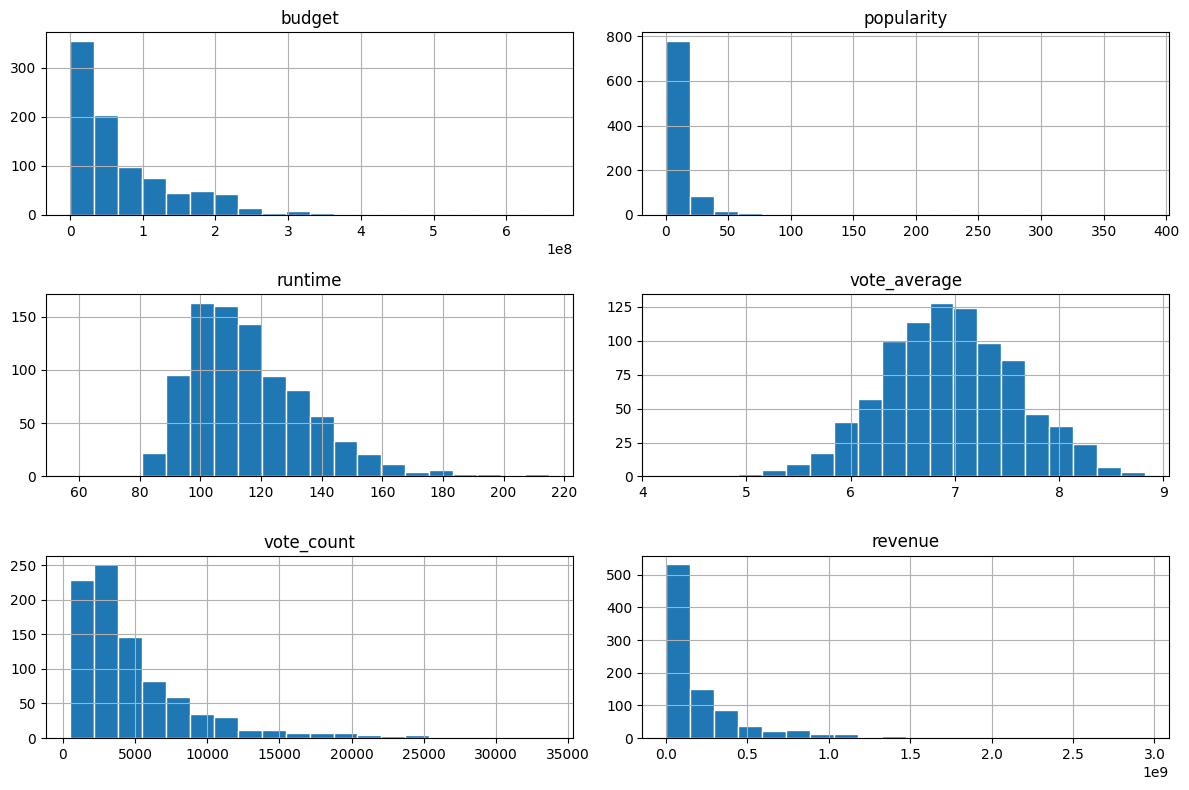

In [355]:
import matplotlib.pyplot as plt

numerical_columns = [
    "budget",
    "popularity",
    "runtime",
    "vote_average",
    "vote_count",
    "revenue"
]

dataCopy[numerical_columns].hist(figsize=(12, 8), bins=20, edgecolor = "white")

plt.tight_layout()
plt.show()


### Histogram Observations

The histograms show the following distributions:

- **Budget:** Strong positive (right) skew. Most movies have relatively low budgets, while a few have very high budgets.
- **Popularity:** Strong positive skew. Most movies have low popularity scores, with a few extremely high values.
- **Runtime:** Slight positive skew. Most movies have runtimes between approximately 90 and 140 minutes.
- **Vote Average:** Approximately symmetric distribution, with most ratings concentrated around 6.5–7.5.
- **Vote Count:** Strong positive skew. Most movies have fewer votes, while a small number have very high vote counts.
- **Revenue:** Strong positive skew. Most movies generate relatively low revenue, while a few movies generate exceptionally high revenue.



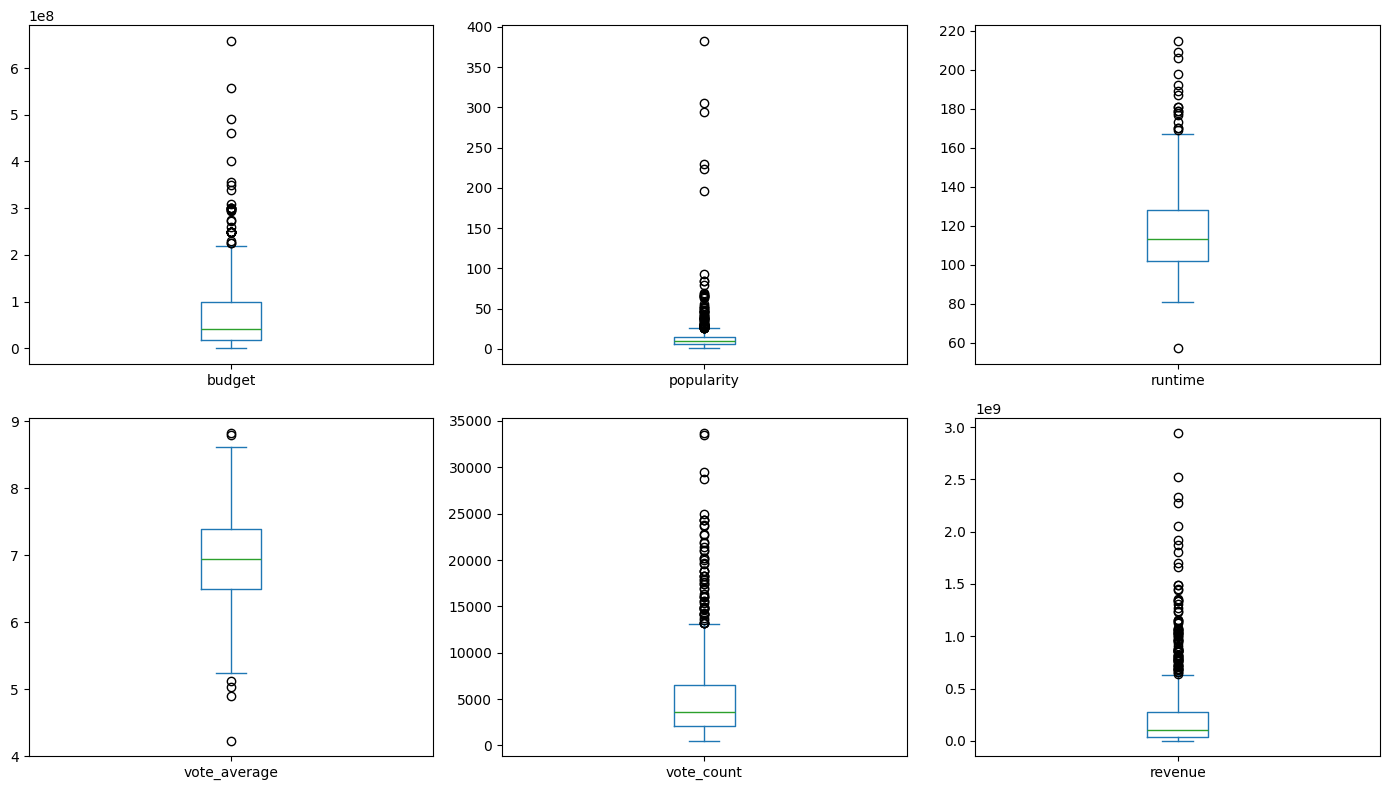

In [356]:
dataCopy[numerical_columns].plot(
    kind="box",
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8)
)

plt.tight_layout()
plt.show()

### Box Plot Observations

The box plots were generated to examine the spread of numerical features and identify potential outliers.

- **Budget:** Several potential outliers are present above the upper whisker, indicating a few movies with exceptionally high budgets.
- **Popularity:** Numerous potential outliers appear above the upper whisker, showing that some movies have unusually high popularity scores.
- **Runtime:** Potential outliers are present on both sides, indicating unusually short and long movies.
- **Vote Average:** A few potential outliers appear at both ends of the distribution.
- **Vote Count:** Numerous potential outliers appear above the upper whisker, indicating that some movies have exceptionally high vote counts.
- **Revenue:** Several potential outliers appear above the upper whisker, showing that a few movies generate exceptionally high revenue.


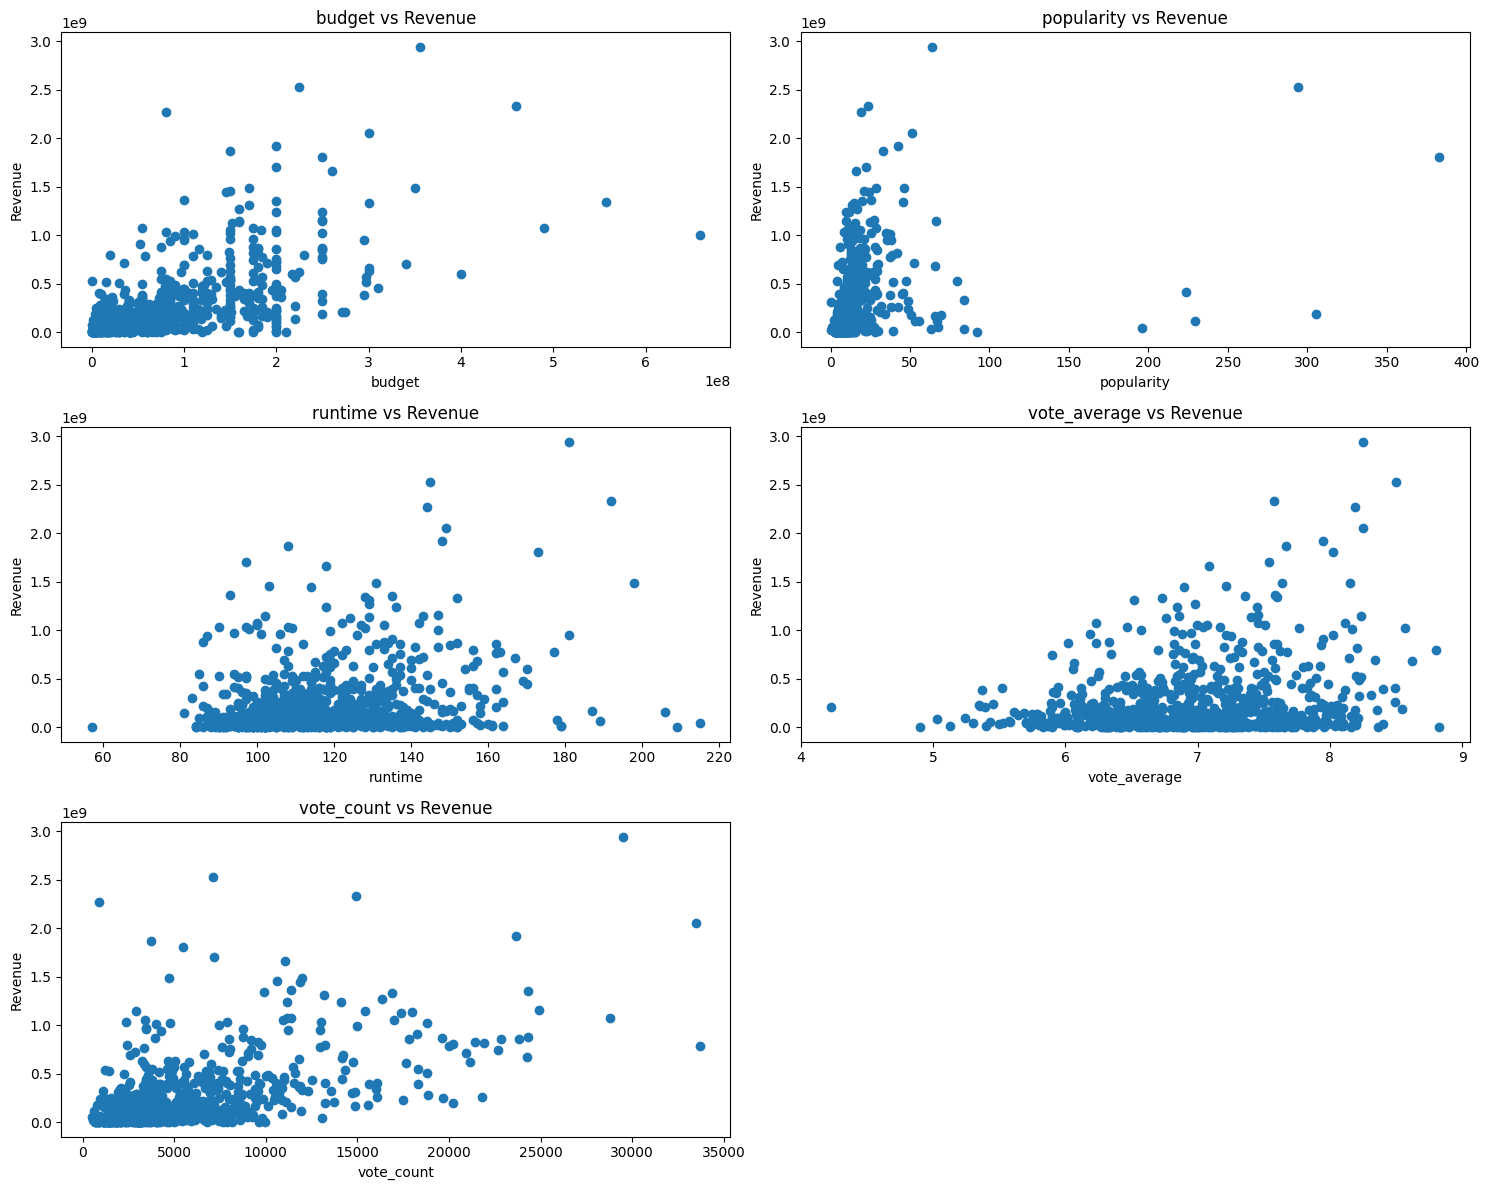

In [357]:
scatter_columns = [
    "budget",
    "popularity",
    "runtime",
    "vote_average",
    "vote_count"
]

plt.figure(figsize=(15, 12))

for i in range(len(scatter_columns)):
    plt.subplot(3, 2, i + 1)

    plt.scatter(dataCopy[scatter_columns[i]], dataCopy["revenue"])

    plt.title(scatter_columns[i] + " vs Revenue")
    plt.xlabel(scatter_columns[i])
    plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

### Scatter Plot Observations

Scatter plots were generated to investigate the relationships between numerical features and movie revenue.

- **Budget vs Revenue:** Shows a positive relationship, as movies with larger budgets generally tend to generate higher revenue.
- **Popularity vs Revenue:** Does not show a clear linear relationship. Revenue varies considerably across different popularity scores.
- **Runtime vs Revenue:** Shows a weak relationship, as longer movies do not consistently generate higher revenue.
- **Vote Average vs Revenue:** Shows a possible positive relationship, although considerable variation exists.
- **Vote Count vs Revenue:** Shows a positive relationship, as movies with higher vote counts generally tend to generate higher revenue.


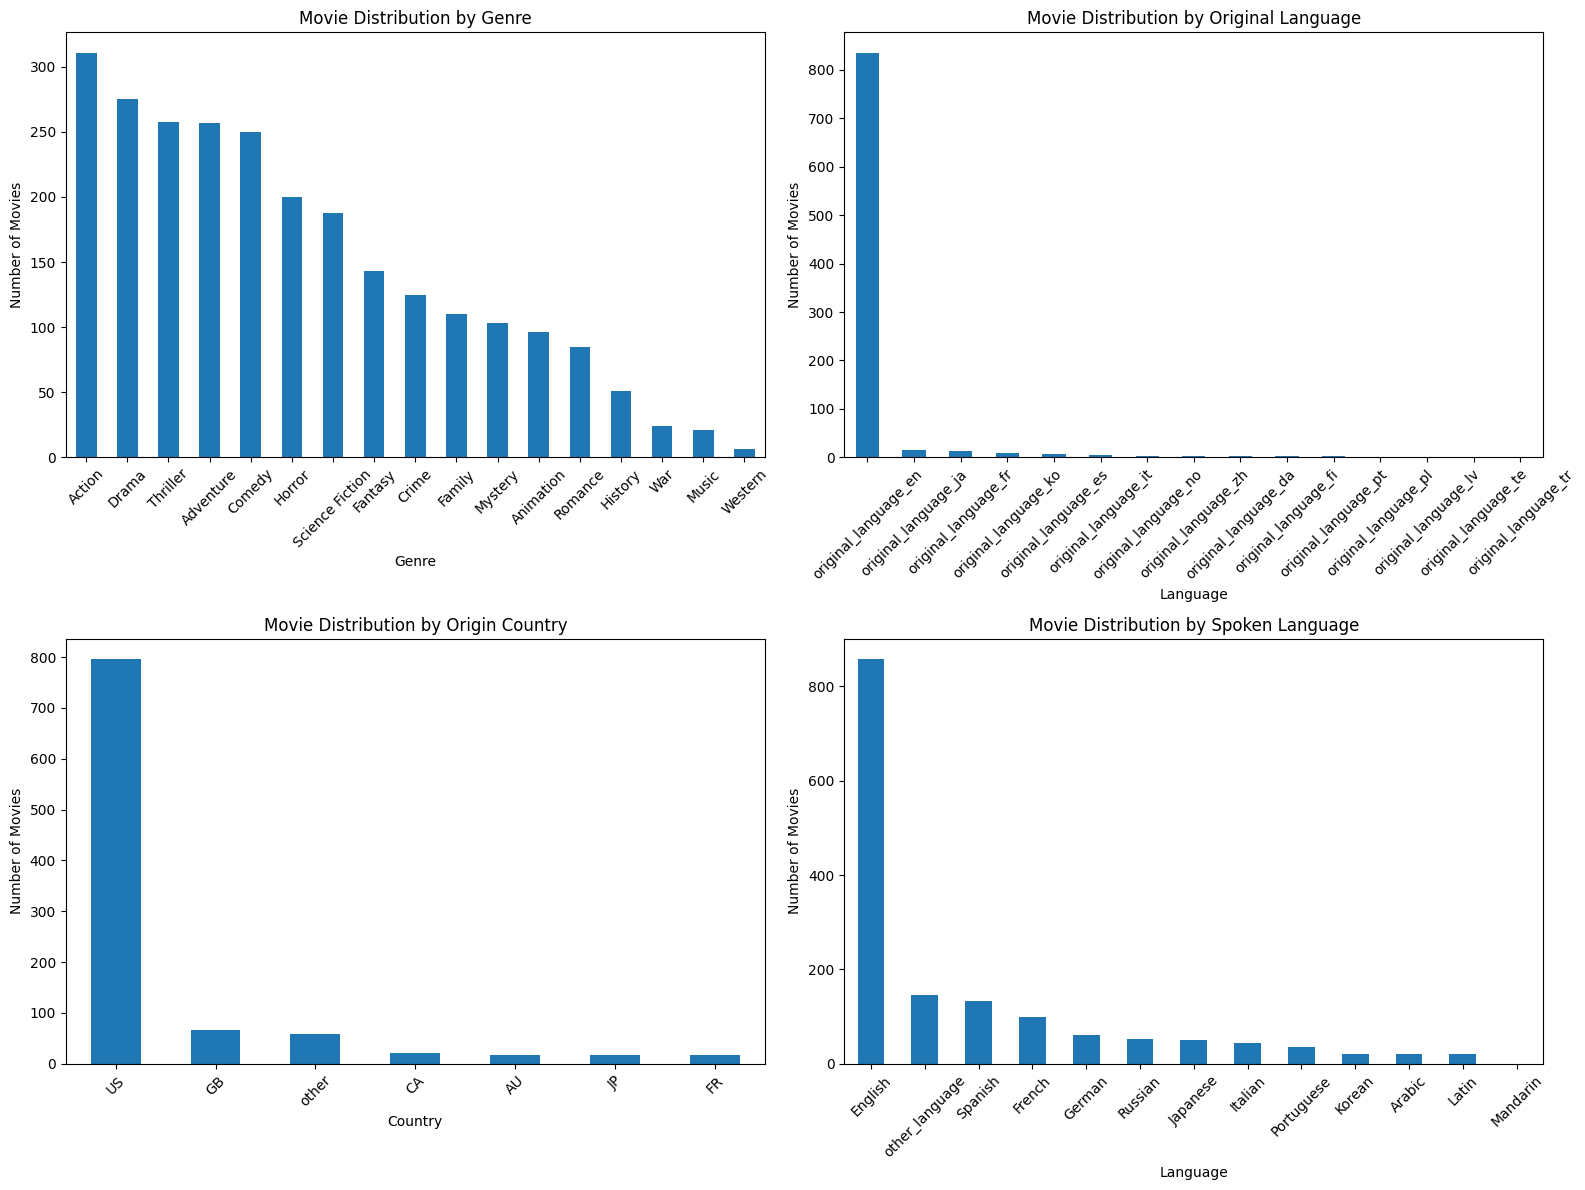

In [358]:
import matplotlib.pyplot as plt

# genre columns
genre_columns = [
    "Action", "Adventure", "Animation", "Comedy", "Crime",
    "Drama", "Family", "Fantasy", "History", "Horror",
    "Music", "Mystery", "Romance", "Science Fiction",
    "Thriller", "War", "Western"
]

# original language columns
original_language_columns = [
    col for col in dataCopy.columns
    if col.startswith("original_language_")
]

# origin country columns
origin_country_columns = [
    "US", "GB", "CA", "AU", "JP", "FR", "other"
]

# spoken language columns
spoken_language_columns = [
    "English", "Spanish", "French", "German", "Russian",
    "Japanese", "Italian", "Mandarin", "Portuguese",
    "Arabic", "Korean", "Latin", "other_language"
]


plt.figure(figsize=(16, 12))

# genre distribution
plt.subplot(2, 2, 1)
dataCopy[genre_columns].sum().sort_values(ascending=False).plot(kind="bar")
plt.title("Movie Distribution by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

# original language distribution
plt.subplot(2, 2, 2)
dataCopy[original_language_columns].sum().sort_values(ascending=False).plot(kind="bar")
plt.title("Movie Distribution by Original Language")
plt.xlabel("Language")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

# origin country distribution
plt.subplot(2, 2, 3)
dataCopy[origin_country_columns].sum().sort_values(ascending=False).plot(kind="bar")
plt.title("Movie Distribution by Origin Country")
plt.xlabel("Country")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

# spoken language distribution
plt.subplot(2, 2, 4)
dataCopy[spoken_language_columns].sum().sort_values(ascending=False).plot(kind="bar")
plt.title("Movie Distribution by Spoken Language")
plt.xlabel("Language")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Observations from Bar Charts

1. **Genre Distribution:** Action is the most common genre, followed by Drama, Thriller, Adventure, and Comedy. Western and Music are among the least frequent genres. Movies can belong to multiple genres.

2. **Original Language Distribution:** English is the dominant original language in the dataset, while the remaining languages have considerably fewer movies.

3. **Origin Country Distribution:** The United States is the most common origin country. The remaining selected countries have much smaller counts. The `other` category represents movies associated with countries outside the six selected countries.

4. **Spoken Language Distribution:** English is the most frequently spoken language, followed by Spanish and French. The `other_language` category represents movies containing languages outside the selected 12 languages.



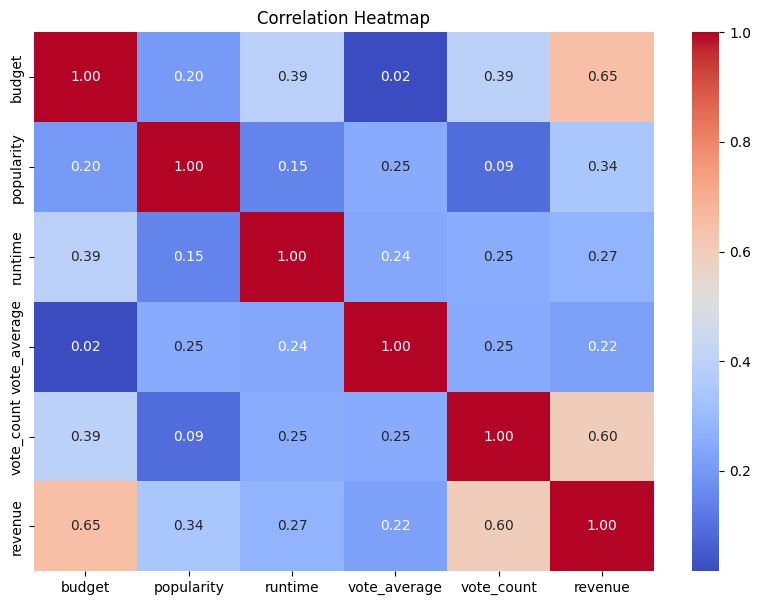

In [359]:
import seaborn as sns

correlation_columns = [
    "budget",
    "popularity",
    "runtime",
    "vote_average",
    "vote_count",
    "revenue"
]

correlation_matrix = dataCopy[correlation_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

### Observations from Correlation Heatmap

1. Budget has the strongest positive correlation with revenue (0.65), followed by vote count (0.60).
2. Popularity (0.31), runtime (0.27), and vote average (0.22) have weaker positive correlations with revenue.
3. Budget and vote count appear to be the most strongly related numerical features to revenue.
4. No extremely high correlations were observed between the input numerical features, suggesting no obvious severe multicollinearity among them.

Overall, budget and vote count show the strongest linear relationships with movie revenue. However, correlation does not imply causation.

In [360]:
dataCopy[numerical_columns].describe()

,budget,popularity,runtime,vote_average,vote_count,revenue
count,8.990000e+02,899.000000,899.000000,899.000000,899.000000,8.990000e+02
mean,7.204078e+07,13.962992,116.496107,6.950961,5130.921023,2.303720e+08
std,7.662537e+07,24.239528,20.003639,0.650158,4660.724349,3.412456e+08
min,7.000000e+00,0.418200,57.000000,4.228000,495.000000,7.000000e+00
25%,1.800000e+07,6.454100,102.000000,6.500000,2126.000000,3.427654e+07
50%,4.200000e+07,9.298600,113.000000,6.949000,3594.000000,1.032234e+08
75%,1.000000e+08,14.061400,128.000000,7.398000,6533.000000,2.749754e+08
max,6.588000e+08,383.102800,215.000000,8.827000,33689.000000,2.942661e+09


### Observations from Summary Statistics

1. All six numerical features contain 899 non-missing observations.
2. Budget, popularity, vote count, and revenue have means considerably higher than their medians, suggesting right-skewed distributions.
3. Runtime has a mean of approximately 116.50 minutes and a median of 113 minutes.
4. Vote average has a mean and median of approximately 6.95, indicating that these values are relatively close.
5. Revenue has a large standard deviation of approximately 341.25 million, showing considerable variation in movie revenues.
6. Budget and revenue have large differences between their minimum and maximum values, indicating substantial variation among movies.

Overall, the summary statistics provide an overview of the central tendency, spread, and range of our numerical features.

In [361]:
# 7. Skewness Analysis and Treatment
numerical_columns = [
    'budget',
    'popularity',
    'revenue',
    'runtime',
    'vote_average',
    'vote_count'
]
skewness = dataCopy[numerical_columns].skew()
print(skewness)
print(skewness.sort_values())
positive_skew = skewness[skewness > 0.5]

negative_skew = skewness[skewness < -0.5]

print("Positively skewed:")
print(positive_skew)

print("\nNegatively skewed:")
print(negative_skew)
print("\nMinimum")
print(dataCopy[numerical_columns].min())

budget          2.117999
popularity      9.834271
revenue         3.114946
runtime         1.089240
vote_average   -0.069952
vote_count      2.351655
dtype: float64
vote_average   -0.069952
runtime         1.089240
budget          2.117999
vote_count      2.351655
revenue         3.114946
popularity      9.834271
dtype: float64
Positively skewed:
budget        2.117999
popularity    9.834271
revenue       3.114946
runtime       1.089240
vote_count    2.351655
dtype: float64

Negatively skewed:
Series([], dtype: float64)

Minimum
budget            7.0000
popularity        0.4182
revenue           7.0000
runtime          57.0000
vote_average      4.2280
vote_count      495.0000
dtype: float64


In [362]:
treatmentData = dataCopy.copy()

# Square root transformation
treatmentData['budget'] = np.sqrt(dataCopy['budget'])
treatmentData['revenue'] = np.sqrt(dataCopy['revenue'])
# we did thi transformation on these features because log transformation
# on these features pushed their skewdness in opposite direction

# Log transformation
treatmentData['popularity'] = np.log1p(dataCopy['popularity'])
treatmentData['vote_count'] = np.log1p(dataCopy['vote_count'])

In [363]:
skew_before = dataCopy[numerical_columns].skew()
skew_after = treatmentData[numerical_columns].skew()

comparison = pd.DataFrame({
    'Before Transformation': skew_before,
    'After Transformation': skew_after
})

print(comparison)

              Before Transformation  After Transformation
budget                     2.117999              0.723235
popularity                 9.834271              1.362188
revenue                    3.114946              1.263675
runtime                    1.089240              1.089240
vote_average              -0.069952             -0.069952
vote_count                 2.351655              0.180050


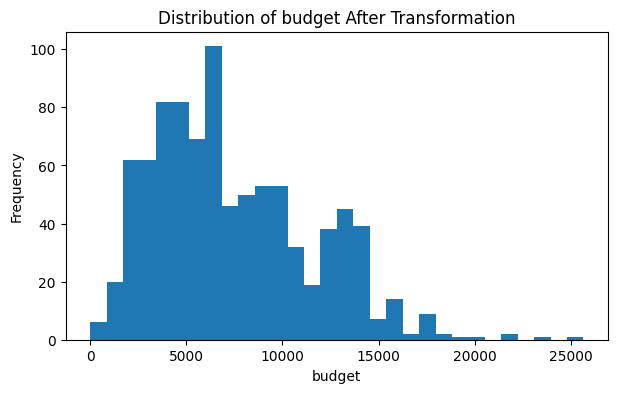

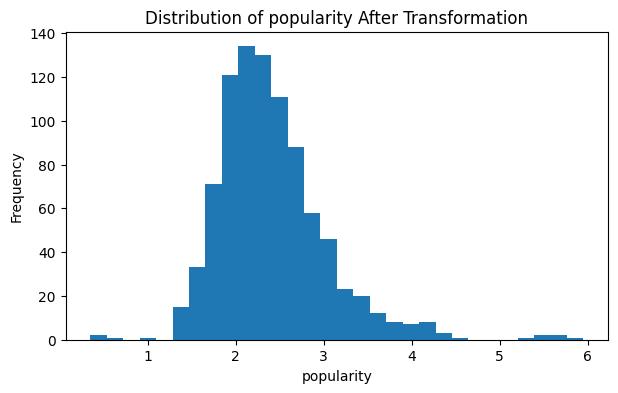

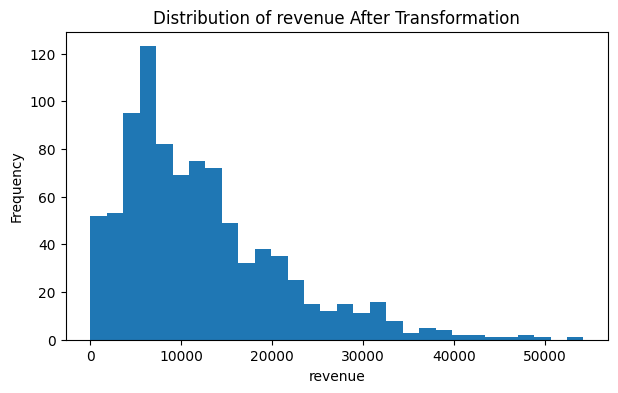

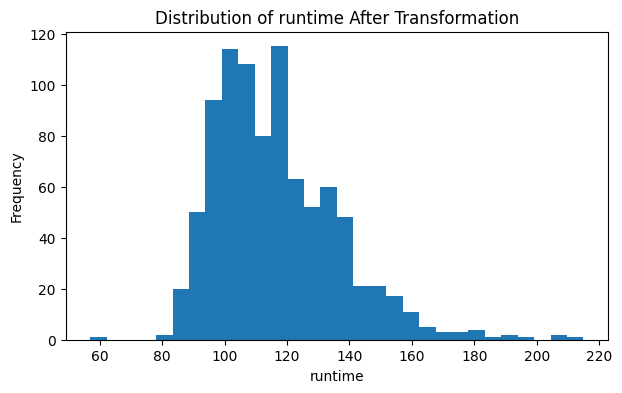

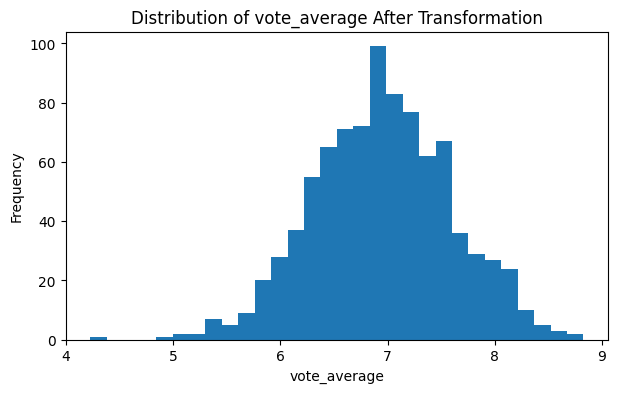

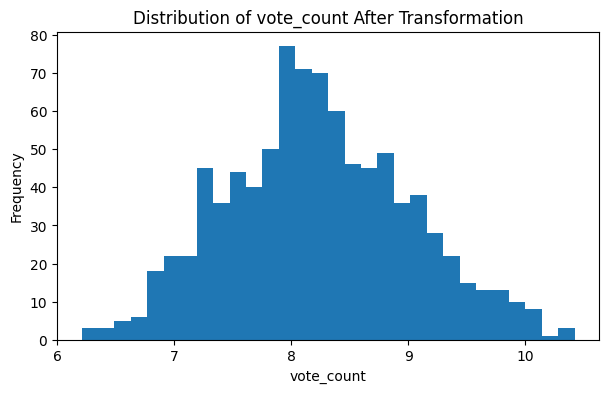

In [364]:
for col in numerical_columns:
    plt.figure(figsize=(7, 4))
    plt.hist(treatmentData[col].dropna(), bins=30)
    plt.title(f'Distribution of {col} After Transformation')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

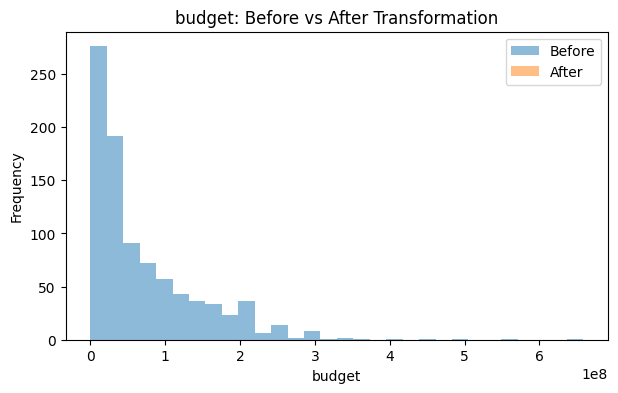

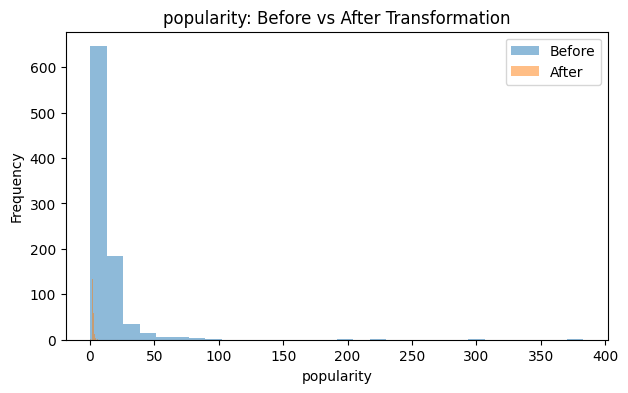

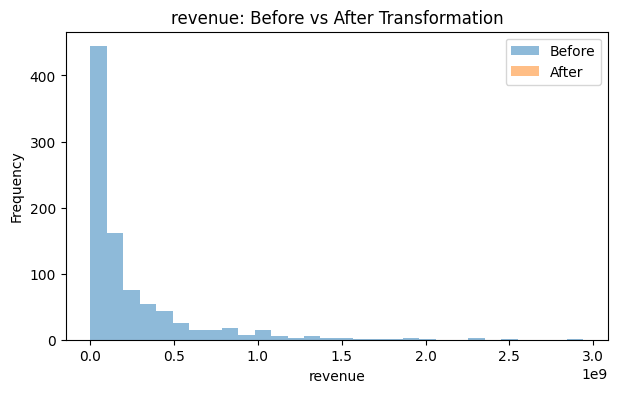

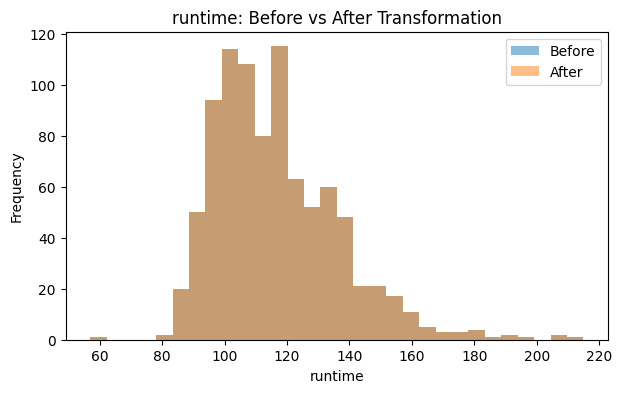

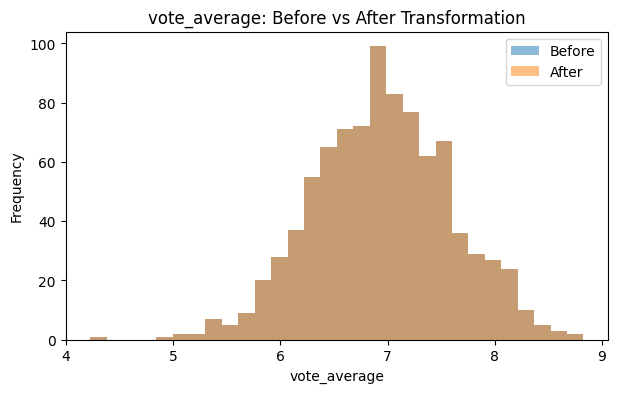

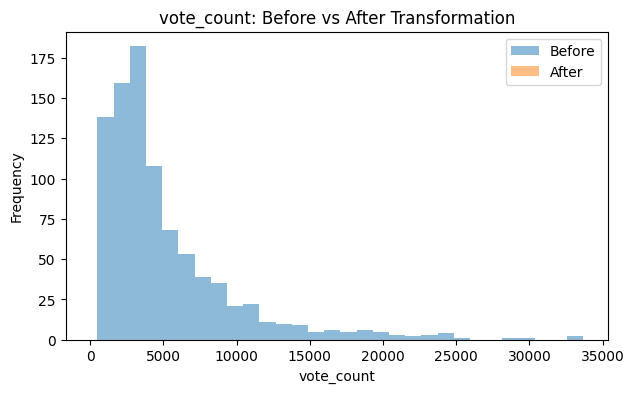

In [365]:
for col in numerical_columns:
    plt.figure(figsize=(7, 4))

    plt.hist(dataCopy[col].dropna(), bins=30, alpha=0.5,
             label='Before')

    plt.hist(treatmentData[col].dropna(), bins=30, alpha=0.5,
             label='After')

    plt.title(f'{col}: Before vs After Transformation')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()

In [366]:
# 8. Outlier Detection Using the IQR Method
Q1 = dataCopy[numerical_columns].quantile(0.25)
Q3 = dataCopy[numerical_columns].quantile(0.75)

print("Q1:")
print(Q1)

print("\nQ3:")
print(Q3)

IQR = Q3 - Q1

print("Interquartile Range:")
print(IQR)

lower_fence = Q1 - (1.5 * IQR)
upper_fence = Q3 + (1.5 * IQR)

print("Lower Fence:")
print(lower_fence)

print("\nUpper Fence:")
print(upper_fence)

Q1:
budget          1.800000e+07
popularity      6.454100e+00
revenue         3.427654e+07
runtime         1.020000e+02
vote_average    6.500000e+00
vote_count      2.126000e+03
Name: 0.25, dtype: float64

Q3:
budget          1.000000e+08
popularity      1.406140e+01
revenue         2.749754e+08
runtime         1.280000e+02
vote_average    7.398000e+00
vote_count      6.533000e+03
Name: 0.75, dtype: float64
Interquartile Range:
budget          8.200000e+07
popularity      7.607300e+00
revenue         2.406989e+08
runtime         2.600000e+01
vote_average    8.980000e-01
vote_count      4.407000e+03
dtype: float64
Lower Fence:
budget         -1.050000e+08
popularity     -4.956850e+00
revenue        -3.267717e+08
runtime         6.300000e+01
vote_average    5.153000e+00
vote_count     -4.484500e+03
dtype: float64

Upper Fence:
budget          2.230000e+08
popularity      2.547235e+01
revenue         6.360237e+08
runtime         1.670000e+02
vote_average    8.745000e+00
vote_count      1.

In [367]:
outliers = {}

for col in numerical_columns:
    lower = lower_fence[col]
    upper = upper_fence[col]

    outlier_values = dataCopy[
        (dataCopy[col] < lower) |
        (dataCopy[col] > upper)
    ][col]

    outliers[col] = len(outlier_values)

print("Number of Potential Outliers:")
print(pd.Series(outliers))

Number of Potential Outliers:
budget          36
popularity      73
revenue         85
runtime         18
vote_average     6
vote_count      59
dtype: int64


In [368]:
for col in numerical_columns:

    lower = lower_fence[col]
    upper = upper_fence[col]

    outlier_values = dataCopy[
        (dataCopy[col] < lower) |
        (dataCopy[col] > upper)
    ][col]

    print(f"\n{col} outliers:")
    print(outlier_values.sort_values(ascending=False).head(10))


budget outliers:
611    658800000.0
800    556800000.0
309    489900000.0
600    460000000.0
918    400000000.0
300    356000000.0
903    350000000.0
706    340000000.0
808    310000000.0
200    300000000.0
Name: budget, dtype: float64

popularity outliers:
1003    383.1028
1044    305.2201
1001    294.2906
1089    229.4784
1015    223.4965
1072    195.9714
1063     92.3152
725      83.7422
1048     83.6997
1002     79.7165
Name: popularity, dtype: float64

revenue outliers:
300     2.942661e+09
1001    2.523148e+09
600     2.334485e+09
998     2.270700e+09
200     2.052415e+09
500     1.921426e+09
913     1.868209e+09
1003    1.804589e+09
802     1.698864e+09
311     1.662021e+09
Name: revenue, dtype: float64

runtime outliers:
852    215
326    209
717    206
903    198
600    192
635    189
684    187
300    181
700    181
597    179
Name: runtime, dtype: int64

vote_average outliers:
1020    8.827
927     8.799
894     5.130
197     5.028
778     4.900
941     4.228
Name: vote_ave

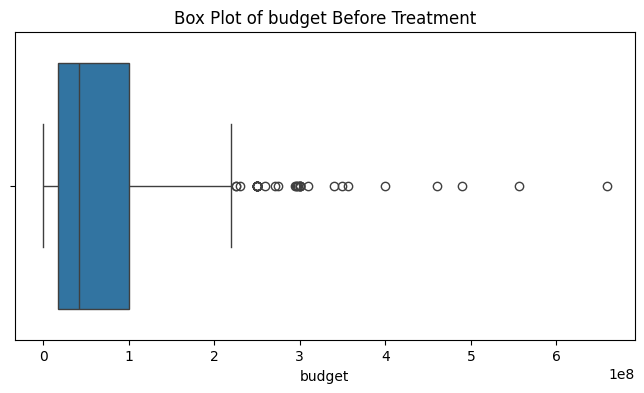

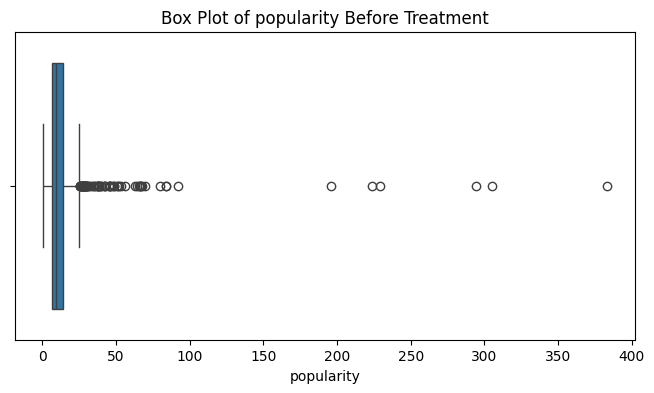

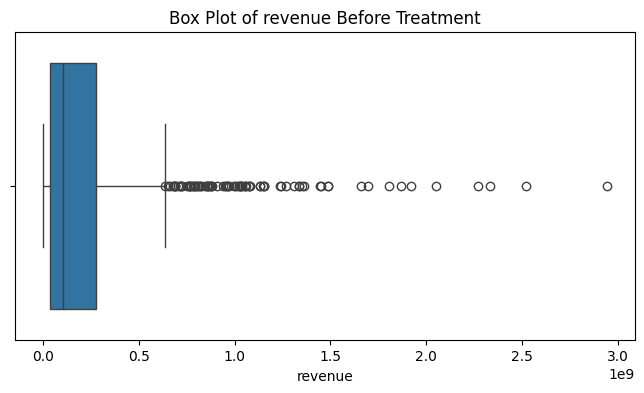

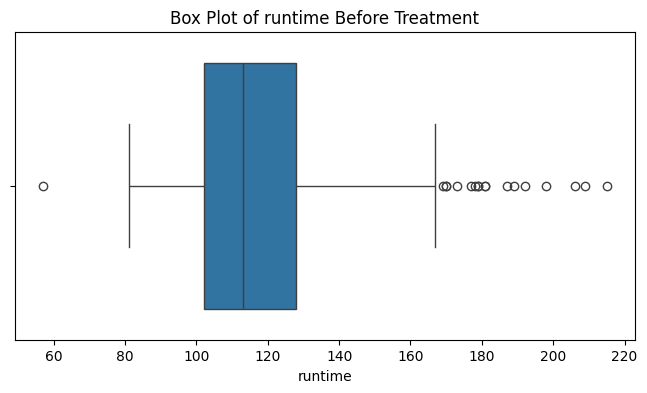

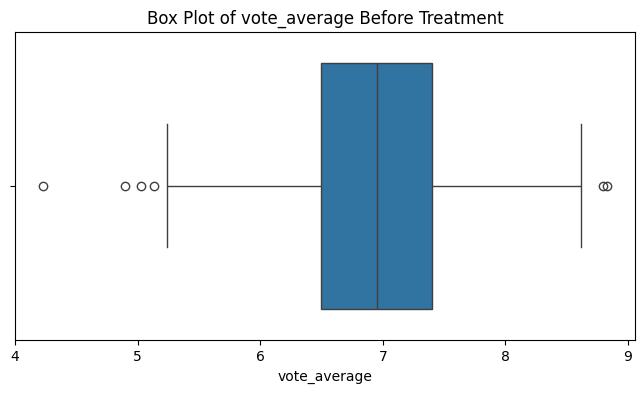

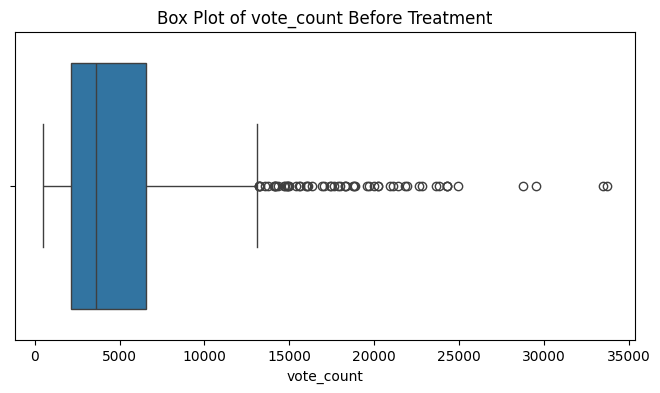

In [369]:
import seaborn as sns


for col in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=dataCopy[col])

    plt.title(f'Box Plot of {col} Before Treatment')
    plt.xlabel(col)

    plt.show()

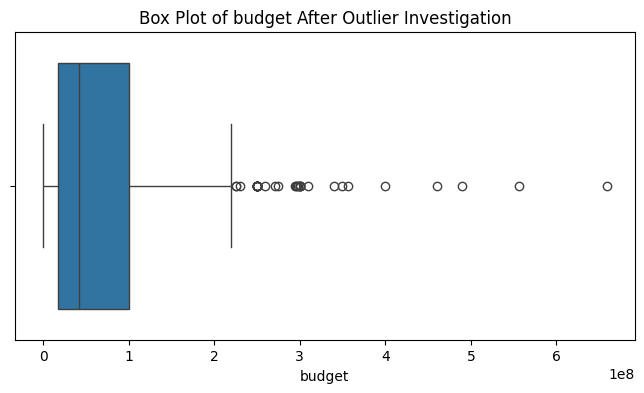

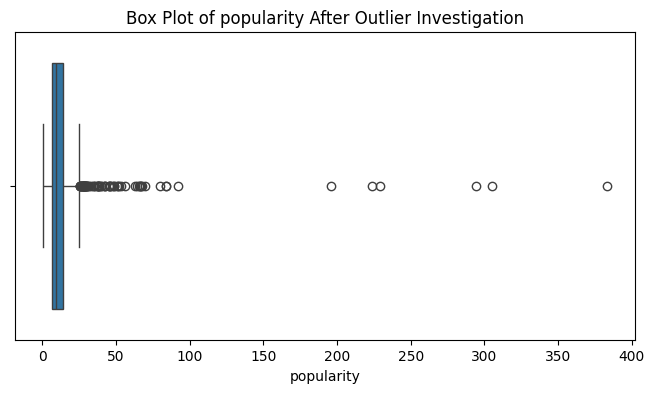

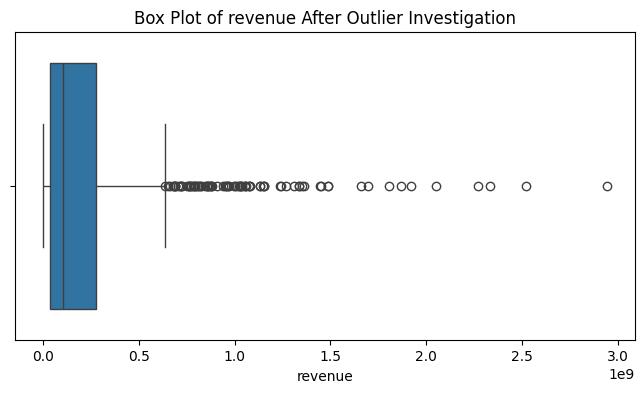

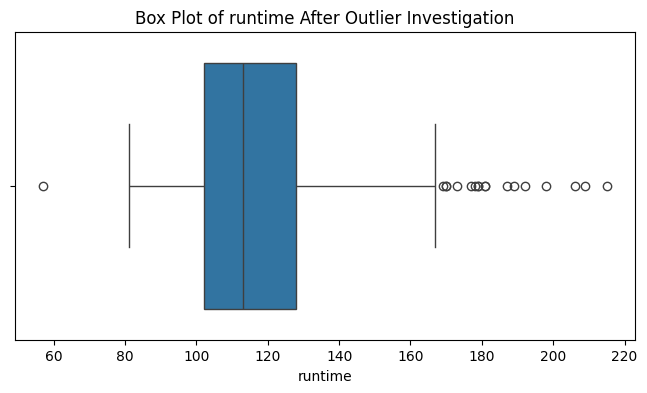

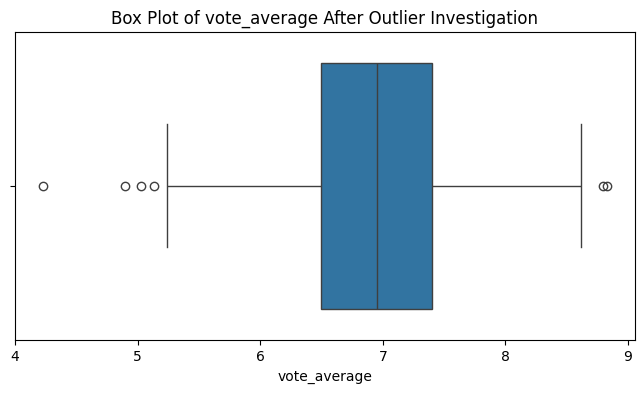

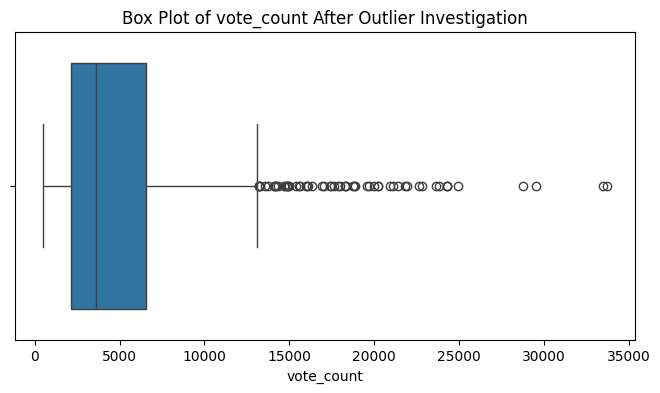

In [370]:
for col in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=dataCopy[col])

    plt.title(f'Box Plot of {col} After Outlier Investigation')
    plt.xlabel(col)

    plt.show()

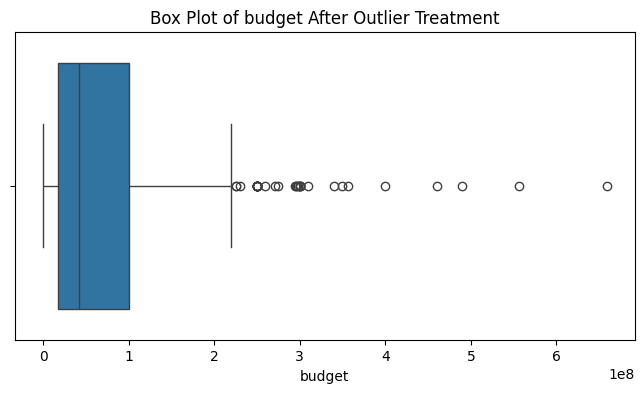

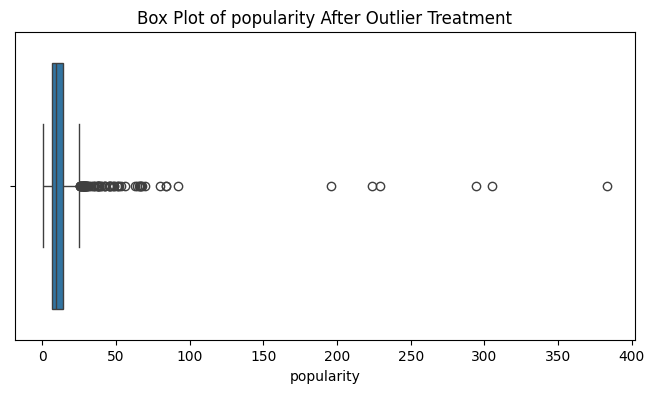

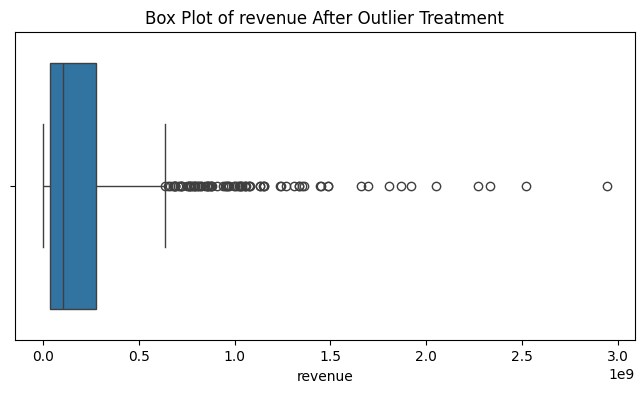

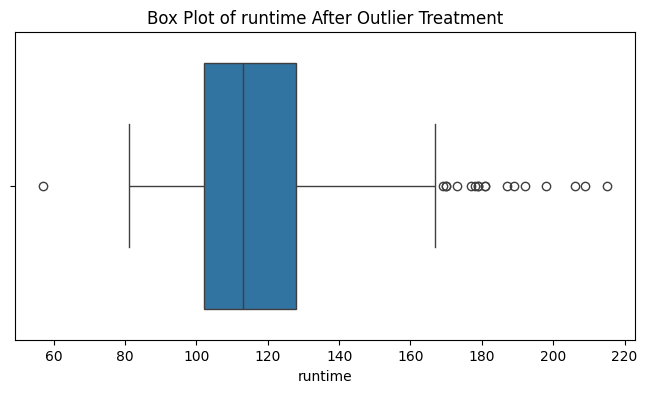

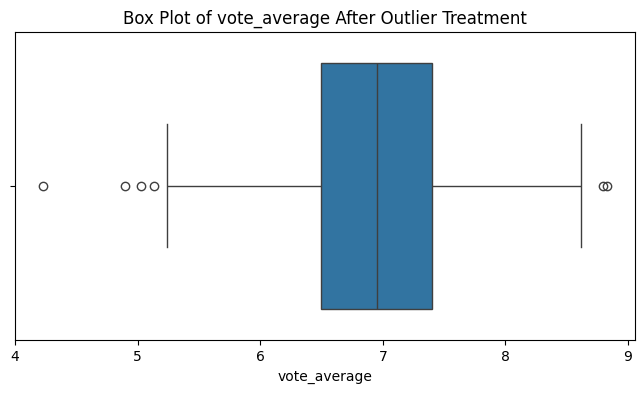

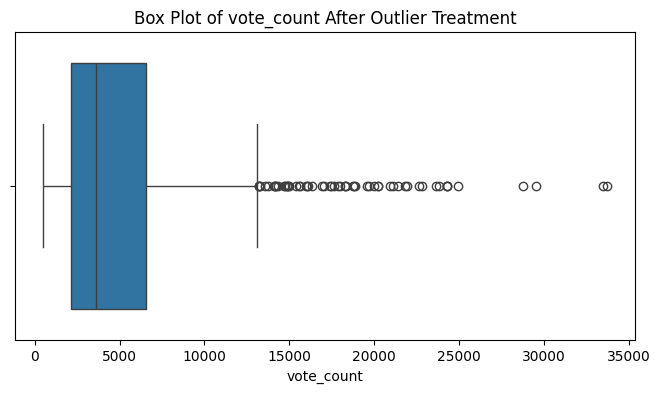

In [371]:
outlier_treated_data = dataCopy.copy()
for col in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=outlier_treated_data[col])

    plt.title(f'Box Plot of {col} After Outlier Treatment')
    plt.xlabel(col)

    plt.show()

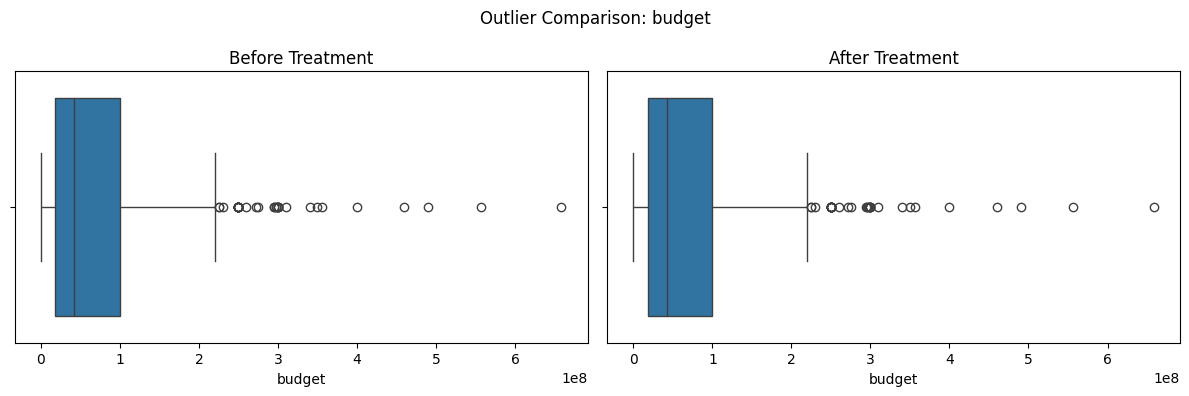

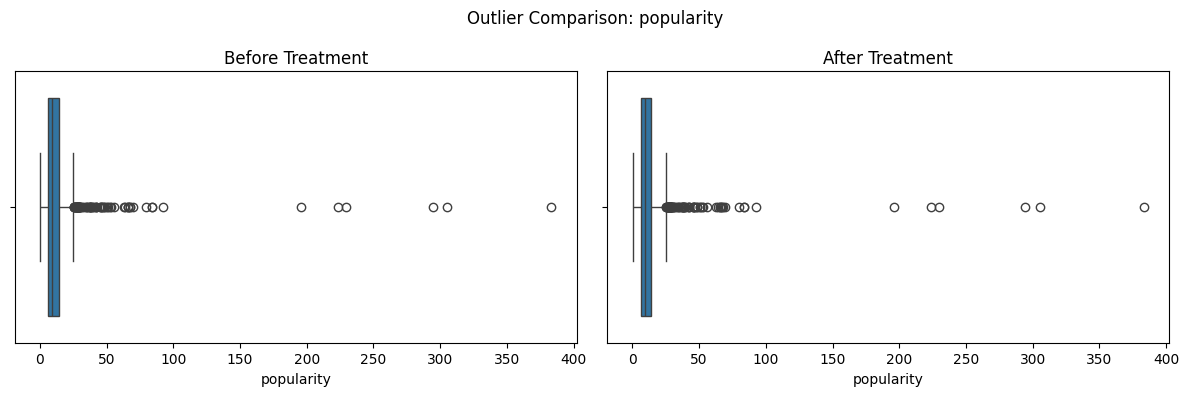

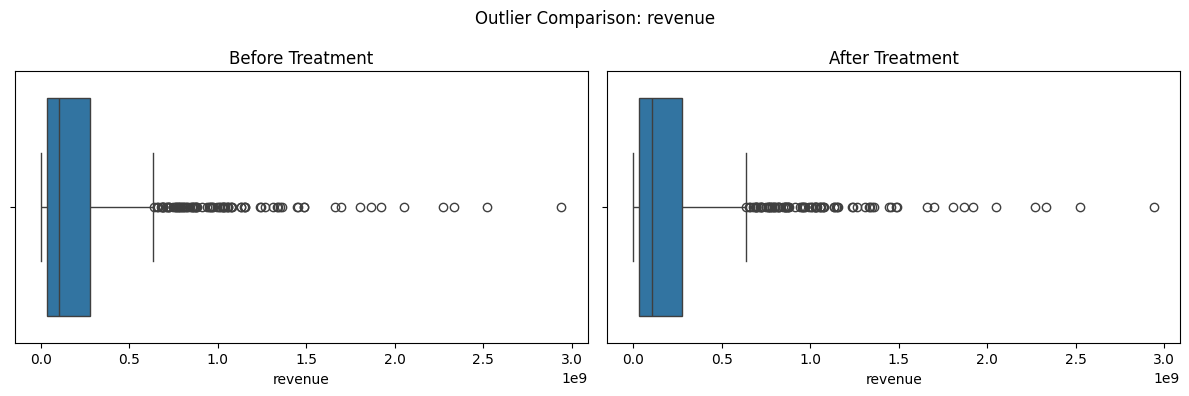

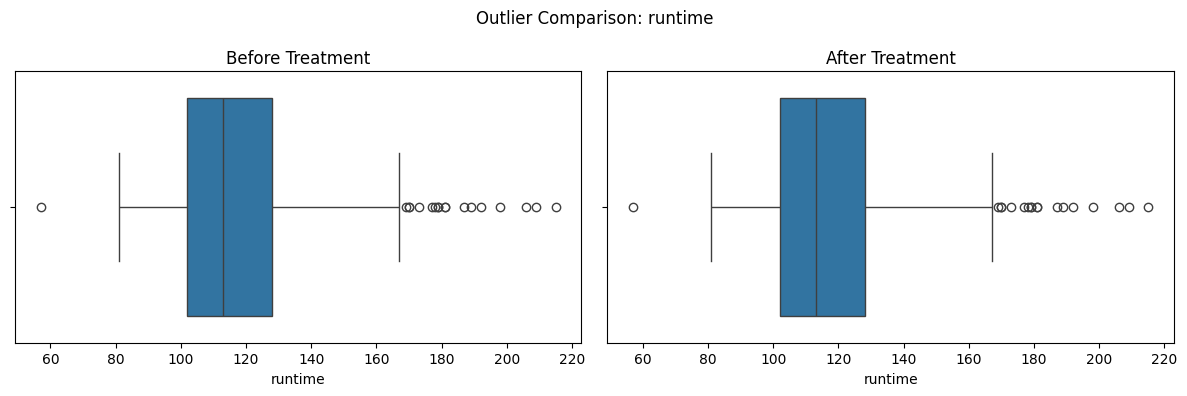

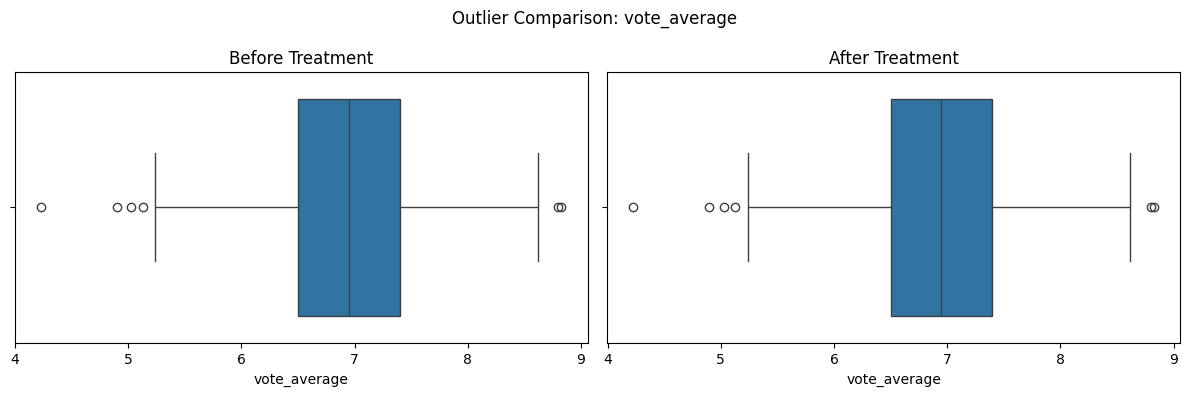

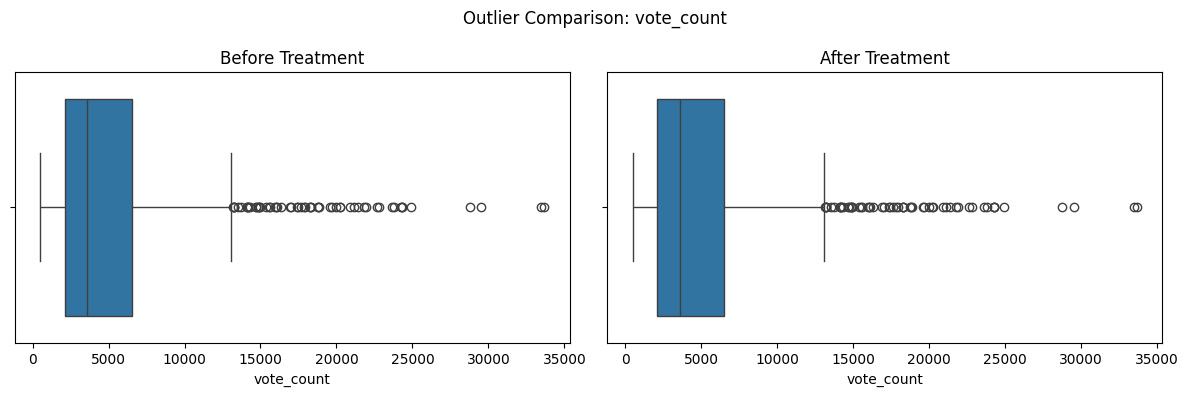

In [372]:
for col in numerical_columns:

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.boxplot(x=dataCopy[col], ax=axes[0])
    axes[0].set_title('Before Treatment')

    sns.boxplot(x=outlier_treated_data[col], ax=axes[1])
    axes[1].set_title('After Treatment')

    fig.suptitle(f'Outlier Comparison: {col}')
    plt.tight_layout()
    plt.show()

In [373]:
# Feature Selection
dataCopy = outlier_treated_data.copy()

Y = dataCopy['revenue']
candidate_features = [
    'budget',
    'runtime',
    'release_year',
    'release_month',
    'belongs_to_collection'
]
X = dataCopy[candidate_features]
Y = dataCopy['revenue']
print(dataCopy.columns.tolist())

['belongs_to_collection', 'budget', 'popularity', 'revenue', 'runtime', 'vote_average', 'vote_count', 'original_language_da', 'original_language_en', 'original_language_es', 'original_language_fi', 'original_language_fr', 'original_language_it', 'original_language_ja', 'original_language_ko', 'original_language_lv', 'original_language_no', 'original_language_pl', 'original_language_pt', 'original_language_te', 'original_language_tr', 'original_language_zh', 'Action', 'Adventure', 'Animation', 'Comedy', 'Crime', 'Drama', 'Family', 'Fantasy', 'History', 'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction', 'Thriller', 'War', 'Western', 'US', 'GB', 'CA', 'AU', 'JP', 'FR', 'other', 'release_year', 'release_month', 'English', 'Spanish', 'French', 'German', 'Russian', 'Japanese', 'Italian', 'Mandarin', 'Portuguese', 'Arabic', 'Korean', 'Latin', 'other_language']


In [374]:
# Numerical and date-related features
basic_features = [
    'budget',
    'runtime',
    'release_year',
    'release_month',
    'belongs_to_collection'
]

# Genre features
genre_features = [
    'Action', 'Adventure', 'Animation', 'Comedy',
    'Crime', 'Drama', 'Family', 'Fantasy',
    'History', 'Horror', 'Music', 'Mystery',
    'Romance', 'Science Fiction', 'Thriller',
    'War', 'Western'
]

# Country features
country_features = [
    'US', 'GB', 'CA', 'AU', 'JP', 'FR', 'other'
]

# Original language features
original_language_features = [
    col for col in dataCopy.columns
    if col.startswith('original_language_')
]

# Spoken language features
spoken_language_features = [
    'English', 'Spanish', 'French', 'German',
    'Russian', 'Japanese', 'Italian', 'Mandarin',
    'Portuguese', 'Arabic', 'Korean', 'Latin',
    'other_language'
]

# Combine all candidate features
candidate_features = (
    basic_features +
    genre_features +
    country_features +
    original_language_features +
    spoken_language_features
)

# Define X and Y
X = dataCopy[candidate_features]
Y = dataCopy['revenue']

print("Input features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(Y.name)

print("\nX shape:", X.shape)
print("Y shape:", Y.shape)

Input features:
['budget', 'runtime', 'release_year', 'release_month', 'belongs_to_collection', 'Action', 'Adventure', 'Animation', 'Comedy', 'Crime', 'Drama', 'Family', 'Fantasy', 'History', 'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction', 'Thriller', 'War', 'Western', 'US', 'GB', 'CA', 'AU', 'JP', 'FR', 'other', 'original_language_da', 'original_language_en', 'original_language_es', 'original_language_fi', 'original_language_fr', 'original_language_it', 'original_language_ja', 'original_language_ko', 'original_language_lv', 'original_language_no', 'original_language_pl', 'original_language_pt', 'original_language_te', 'original_language_tr', 'original_language_zh', 'English', 'Spanish', 'French', 'German', 'Russian', 'Japanese', 'Italian', 'Mandarin', 'Portuguese', 'Arabic', 'Korean', 'Latin', 'other_language']

Target variable:
revenue

X shape: (899, 57)
Y shape: (899,)


In [375]:
# verifying if data is okay to be used in model training
print("Missing values in X:")
print(X.isnull().sum().sum())

print("\nMissing values in Y:")
print(Y.isnull().sum())

print("\nDuplicate columns:")
print(X.columns[X.columns.duplicated()].tolist())

Missing values in X:
0

Missing values in Y:
0

Duplicate columns:
[]


/tmp/ipykernel_731/1372859178.py:3: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  print(X.isnull().sum().sum())


In [376]:
print(X.dtypes.value_counts())
print(X.shape)
print(Y.shape)
print(X.dtypes)
print(X[basic_features].describe())

int64                 39
Sparse[float64, 0]    15
int32                  2
float64                1
Name: count, dtype: int64
(899, 57)
(899,)
budget                              float64
runtime                               int64
release_year                          int32
release_month                         int32
belongs_to_collection                 int64
Action                                int64
Adventure                             int64
Animation                             int64
Comedy                                int64
Crime                                 int64
Drama                                 int64
Family                                int64
Fantasy                               int64
History                               int64
Horror                                int64
Music                                 int64
Mystery                               int64
Romance                               int64
Science Fiction                       int64
Thriller             

In [377]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (719, 57)
Testing features: (180, 57)


In [378]:
estimator = make_pipeline(
    StandardScaler(with_mean=False),
    LinearRegression()
)
forward_selector = SequentialFeatureSelector(
    estimator,
    n_features_to_select="auto",
    direction="forward",
    scoring="r2",
    cv=5,
    tol=0.001,
    n_jobs=-1
)
forward_selector.fit(X_train, Y_train)
selected_features_forward = X_train.columns[
    forward_selector.get_support()
].tolist()

print("Selected features:")
print(selected_features_forward)

print("\nNumber of selected features:")
print(len(selected_features_forward))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(


Selected features:
['budget', 'runtime', 'release_year', 'belongs_to_collection', 'Action', 'Adventure', 'Crime', 'Thriller', 'French']

Number of selected features:
9


In [379]:
# Saved for later use
X_train_forward = X_train[selected_features_forward]
X_test_forward = X_test[selected_features_forward]

In [380]:
backward_selector = SequentialFeatureSelector(
    estimator,
    n_features_to_select="auto",
    direction="backward",
    scoring="r2",
    cv=5,
    tol=-0.001,
    n_jobs=-1
)

backward_selector.fit(X_train, Y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(


SequentialFeatureSelector(direction='backward',
                          estimator=Pipeline(steps=[('standardscaler',
                                                     StandardScaler(with_mean=False)),
                                                    ('linearregression',
                                                     LinearRegression())]),
                          n_jobs=-1, scoring='r2', tol=-0.001)

In [381]:
selected_features_backward = X_train.columns[
    backward_selector.get_support()
].tolist()

print("Selected features:")
print(selected_features_backward)

print("\nNumber of selected features:")
print(len(selected_features_backward))
# This shows that both forward and backward method give same results

Selected features:
['budget', 'runtime', 'release_year', 'belongs_to_collection', 'Action', 'Adventure', 'Crime', 'Thriller', 'French']

Number of selected features:
9


In [382]:
selected_features = selected_features_forward

X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print(X_train_selected.shape)
print(X_test_selected.shape)

(719, 9)
(180, 9)


In [383]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

numerical_features = ['budget', 'runtime', 'release_year']

preprocessor = ColumnTransformer(
    transformers=[
        ('scale', StandardScaler(), numerical_features)
    ],
    remainder='passthrough'
)

# Training Linear Regression

In [384]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

In [385]:
lr_model = Pipeline([
    ('preprocessing', preprocessor),
    ('regression', LinearRegression())
])
lr_model.fit(X_train_selected, Y_train) #point where we train model

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scale', StandardScaler(),
                                                  ['budget', 'runtime',
                                                   'release_year'])])),
                ('regression', LinearRegression())])

In [386]:
Y_pred_lr = lr_model.predict(X_test_selected)
print("Actual revenue:", Y_test.values[:5])
print("Predicted revenue:", Y_pred_lr[:5])

Actual revenue: [6.46865150e+07 4.05663810e+07 6.18723803e+08 7.58366830e+07
 1.40312928e+08]
Predicted revenue: [ 2.03237385e+08 -1.51618674e+07  7.33775938e+08  1.92392258e+08
  7.71335285e+07]


# Linear Regression Analysis

In [387]:
# Linear Regression Model Analysis
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
mae = mean_absolute_error(Y_test, Y_pred_lr)

mse = mean_squared_error(Y_test, Y_pred_lr)

rmse = np.sqrt(mse)

r2 = r2_score(Y_test, Y_pred_lr)

print("Linear Regression Results")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
MAE: 143287654.67819497
MSE: 5.78093231385334e+16
RMSE: 240435694.39360163
R2 Score: 0.4375820700446805


In [388]:
Y_train_pred_lr = lr_model.predict(X_train_selected)

train_r2 = r2_score(Y_train, Y_train_pred_lr)
test_r2 = r2_score(Y_test, Y_pred_lr)

print("Training R2:", train_r2)
print("Testing R2:", test_r2)

Training R2: 0.5241193744224983
Testing R2: 0.4375820700446805


# Training Decison Tree

In [389]:
from sklearn.tree import DecisionTreeRegressor
dt_model = Pipeline([
    ('preprocessing', preprocessor),
    ('regression', DecisionTreeRegressor(random_state=42))
])
dt_model.fit(X_train_selected, Y_train)
Y_pred_dt = dt_model.predict(X_test_selected)


# Evaluating Decision Tree

In [390]:
mae_dt = mean_absolute_error(Y_test, Y_pred_dt)

mse_dt = mean_squared_error(Y_test, Y_pred_dt)

rmse_dt = np.sqrt(mse_dt)

r2_dt = r2_score(Y_test, Y_pred_dt)

print("Decision Tree Results")
print("MAE:", mae_dt)
print("MSE:", mse_dt)
print("RMSE:", rmse_dt)
print("R2:", r2_dt)

Decision Tree Results
MAE: 172640272.75
MSE: 8.706959834445502e+16
RMSE: 295075580.73221684
R2: 0.15291339520478853


In [391]:
Y_train_pred_dt = dt_model.predict(X_train_selected)

train_r2_dt = r2_score(Y_train, Y_train_pred_dt)
test_r2_dt = r2_score(Y_test, Y_pred_dt)

print("Training R2:", train_r2_dt)
print("Testing R2:", test_r2_dt)

Training R2: 1.0
Testing R2: 0.15291339520478853


Since the model is severely overfit, we will try hyper tuning

In [392]:
dt_model_tuned = Pipeline([
    ('preprocessing', preprocessor),
    ('regression', DecisionTreeRegressor(
        max_depth=5,
        min_samples_leaf=5,
        random_state=42
    ))
])

In [393]:
dt_model_tuned.fit(X_train_selected, Y_train)
Y_pred_dt_tuned = dt_model_tuned.predict(X_test_selected)

Y_train_pred_dt_tuned = dt_model_tuned.predict(X_train_selected)


In [394]:
print("Training R2:",
      r2_score(Y_train, Y_train_pred_dt_tuned))

print("Testing R2:",
      r2_score(Y_test, Y_pred_dt_tuned))

Training R2: 0.6144640694501046
Testing R2: 0.4259921655971407


# Training Random Forest

In [395]:
from sklearn.ensemble import RandomForestRegressor
rf_model = Pipeline([
    ('preprocessing', preprocessor),
    ('regression', RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])
rf_model.fit(X_train_selected, Y_train)

Y_pred_rf = rf_model.predict(X_test_selected)
Y_train_pred_rf = rf_model.predict(X_train_selected)


# Evaluating the Random Forest

In [396]:
mae_rf = mean_absolute_error(Y_test, Y_pred_rf)

mse_rf = mean_squared_error(Y_test, Y_pred_rf)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(Y_test, Y_pred_rf)

print("Random Forest Results")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2:", r2_rf)

Random Forest Results
MAE: 130423150.102
MSE: 5.757625018943881e+16
RMSE: 239950516.12663558
R2: 0.4398496005819994


In [397]:
train_r2_rf = r2_score(Y_train, Y_train_pred_rf)
test_r2_rf = r2_score(Y_test, Y_pred_rf)

print("Training R2:", train_r2_rf)
print("Testing R2:", test_r2_rf)

Training R2: 0.9196372110956165
Testing R2: 0.4398496005819994


# Comparing All 3 Models

In [398]:
results = {
    'Linear Regression': [
        mean_absolute_error(Y_test, Y_pred_lr),
        mean_squared_error(Y_test, Y_pred_lr),
        np.sqrt(mean_squared_error(Y_test, Y_pred_lr)),
        r2_score(Y_test, Y_pred_lr)
    ],

    'Decision Tree': [
        mean_absolute_error(Y_test, Y_pred_dt_tuned),
        mean_squared_error(Y_test, Y_pred_dt_tuned),
        np.sqrt(mean_squared_error(Y_test, Y_pred_dt_tuned)),
        r2_score(Y_test, Y_pred_dt_tuned)
    ],

    'Random Forest': [
        mean_absolute_error(Y_test, Y_pred_rf),
        mean_squared_error(Y_test, Y_pred_rf),
        np.sqrt(mean_squared_error(Y_test, Y_pred_rf)),
        r2_score(Y_test, Y_pred_rf)
    ]
}

comparison_df = pd.DataFrame(
    results,
    index=['MAE', 'MSE', 'RMSE', 'R2']
).T

print(comparison_df)

                            MAE           MSE          RMSE        R2
Linear Regression  1.432877e+08  5.780932e+16  2.404357e+08  0.437582
Decision Tree      1.319398e+08  5.900062e+16  2.429004e+08  0.425992
Random Forest      1.304232e+08  5.757625e+16  2.399505e+08  0.439850


In [399]:
dataCopy.to_csv("CleanedData.csv", index = False)